---
title: "The Mears criteria: what each transport-limit test actually guarantees"
description: "Mears (1971) collects the diagnostic inequalities that decide whether a measured rate is chemistry or transport, each claiming a 5 % tolerance. This page solves the pellet, film and dispersion problems exactly and measures what each criterion's boundary really admits: the one that is exact, the ones the rounding broke, the window where one loses all power, and the limit where the combined criterion fails structurally."
categories: [sec:B, struct:S3, struct:S4, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-06
---

# The Mears criteria: what each transport-limit test actually guarantees

**Catalog ID:** `B1.7` · **Structures:** `S3` (1D steady BVP) + `S4` (axial dispersion) · **Tier:** T0

An experimenter measures a rate. Before that number can be called kinetics,
gradients must be ruled out in three domains: *intraparticle* (inside the
pellet), *interphase* (across the film around it) and *interparticle* (across
the reactor). Mears (1971) collects, and in three cases derives, one-line
inequalities in **observables** for each domain, almost all carrying the same
promise: satisfy this, and the measured rate deviates from the true one by less
than 5 %.

Those inequalities are still the standard screening tests. What none of them
comes with is a measurement of what the promise is worth: the derivations are
first-order perturbation expansions, several right-hand sides are rounded, and
one is stated with an unquantified exclusion zone. [`B1.4`](../B1.4-weisz-prater-criterion/)
does this audit for the Weisz-Prater criterion alone; this page does it for the
rest of the family. Every criterion the paper prints is solved against exactly,
and the page reports, per criterion, the deviation its boundary actually admits:

1. **One criterion is exact.** The interphase mass test (eq. 17) holds its 5 %
   to all digits for first-order kinetics, because the film balance makes the
   deviation *equal* to a third of the criterion's own left side.
2. **The intraparticle family is uniformly liberal by the same rounding.** The
   paper says "a numerical value of 0.75 … was rounded to 1". That rounding is
   the gap between the stated 5 % and what the printed bounds admit.
3. **The nonisothermal criterion (eq. 9) has a measurable window of no
   power.** Its bound diverges at the compensation point $n = \gamma\beta$;
   the exact 5 % threshold stays finite, so near compensation the criterion
   certifies states with arbitrarily large deviations, and the page computes
   the window of $\gamma\beta$ in which even the unrounded 0.75 cannot save it.
4. **The combined interphase-intraparticle criterion (eq. 21) fails
   structurally at low Biot number**, and passing every pellet-scale criterion
   at once still admits more than twice the 5 %, because the tolerances stack.
5. **The axial-dispersion criterion (eq. 30), Mears' own, holds its claim** at
   every conversion and order tested.

The numbers behind each statement are printed by the code below and collected
in *What pymrm adds*.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B1.7-mears-criteria"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import brentq, minimize_scalar
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, load_claims
from model import (Power, WeiszHicks, InhibitedLH, shoot, cross, eta_iso1,  # this page's model.py
                   Pellet, film_mass_dev, film_heat_dev, AxialVessel, frac_unconverted,
                   axial_dev, axial_dev_covary, petersen_dev, joint_worst)

np.seterr(all="ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
BREAK = []
B14 = load_claims("B1.4-weisz-prater-criterion")   # numbers this page compares with


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught

## Background

The forward problem, given kinetics compute the transport-corrupted rate, is
what [`B1.1`](../B1.1-thiele-weisz-hicks/) solves. The experimenter faces the
inverse problem: the intrinsic kinetics are what the experiment is *for*, so a
usable test must be stated in measured quantities only. The classic example is
Weisz and Prater's group $\Phi = \mathcal{R}\,r_p^2/(C_s D_e)$ (observed rate
per particle volume, particle radius, surface concentration, effective
diffusivity) with the criterion $\Phi < 1$.

Mears' 1971 review assembles the whole toolbox in that spirit and extends it.
Its route to each criterion is *perturbation analysis*: expand the rate in a
Taylor series in the concentration and temperature perturbations, and bound the
group of observables that keeps the first-order rate deviation below a stated
tolerance, usually 5 %. That construction has two systematic consequences this
page measures. First, a first-order expansion is only as good as the curvature
it drops, so each boundary sits slightly off the true 5 % contour, sometimes on
the safe side and sometimes not, and in the intraparticle family the deliberate
rounding of 0.75 to 1 moves it further. Second, wherever two effects cancel at
first order (the $n = \gamma\beta$ compensation case), the criterion's
denominator vanishes and the test loses all power; the paper says the case
"requires further consideration", and this page measures how wide it is.

The paper contains no data, no figures and no tables: every claim in it is an
inequality plus prose. The criteria are inequalities between computable
quantities, so the validation is to solve the underlying pellet, film and
reactor problems exactly and measure where each stated tolerance holds, where it
fails, and by how much.

## The published model

### Provenance: what was read, and where each criterion comes from

**Mears, D. E. (1971), "Tests for Transport Limitations in Experimental
Catalytic Reactors", *Ind. Eng. Chem. Process Des. Develop.* 10(4), 541-547, is
the only document consulted.** The scan is CCITT-G4 bilevel at 300 ppi native;
every equation and every numeric threshold below was read off cropped 300 dpi
renders (`pdftoppm -r 300`) of the journal page named, because the text layer
loses exactly the load-bearing symbols: the effectiveness factor extracts as a
bare comma, eq. (25)'s right side `5.3` comes back as a degree sign and a dash,
and eq. (3)'s $1/|n|$ loses its absolute-value bars. The PDF also opens with the
tail of the *preceding* article (a catalytic-cracking study), so identity was
established from page 2 onward, the running head, and the ACS download stamp
`article-pdf/10/4/541/`.

**This paper is a review, and the three criteria "derived by the author" are
derived in two companion papers, not here.** The interphase criteria (eqs. 14,
17) and the interparticle radial criterion (eq. 23) cite "Mears, 1971b"
(*J. Catal.* **20**, 127); the axial criterion (eqs. 29-32) cites "Mears,
1971a" (*Chem. Eng. Sci.*, listed "in press"). **Neither companion was
consulted**; this page audits the criteria exactly as the review states them,
which is also how the literature cites them. The remaining criteria are
attributed by the review to Weisz & Prater (1954), Weisz (1957), Hudgins (1968),
Anderson (1963), Kubota & Yamanaka (1969), Weisz & Hicks (1962), Carberry
(1961), Satterfield et al. (1969), van den Bleek et al. (1969) and Petersen
(1965b, 1968); none of those was consulted either.

### The criteria, as printed

All symbols as in the paper's Nomenclature (journal page 547): $\mathcal{R}$ is
the **observed** rate per unit particle volume, $r_p$ the particle **radius**,
$d_p$ its diameter, $C_s$/$C_b$ the surface/bulk reactant concentration, $D_e$
the effective diffusivity, $\lambda$ the particle conductivity, $h$/$k_c$ the
film heat/mass transfer coefficients, $n$ the power-law order, $E$ the true
activation energy.

**Intraparticle, isothermal** (journal pages 542-543):

$$\frac{\mathcal{R}r_p^2}{C_sD_e} < 1 \tag{1}$$

(Weisz-Prater; first order, sphere, $\eta \ge 0.95$), with Weisz (1957)'s
linear-approximation values "conservatively 0.3 for second-order reactions and
6 for zero order", 0.6 for first order;

$$\frac{\mathcal{R}r_p^2}{C_sD_e} < \frac{\mathcal{R}_s}{C_s\mathcal{R}'_{cs}} \tag{2}$$

(Hudgins 1968, $\eta > 0.95$, "a numerical value of 0.75 … was rounded to 1",
extendable to negative orders "by taking the absolute value of the
derivative"), which for power-law kinetics becomes

$$\frac{\mathcal{R}r_p^2}{C_sD_e} < \frac{1}{|n|} \tag{3}$$

(eqs. 2 and 3 "fail for zero-order kinetics … the value of 6 on the right
obtained by Weisz is recommended").

**Intraparticle, thermal** (page 542): Anderson's quasi-isothermality test,
"the observed rate $\mathcal{R}$ must not differ from the rate that would
prevail at constant temperature by more than an acceptable amount, say 5 %",
with "again a numerical value of 0.75 on the right … rounded to 1", valid
"whether diffusional limitations exist in the particle or not":

$$\frac{|\Delta H|\mathcal{R}r_p^2}{\lambda T_s} < \frac{T_sR}{E} \tag{6}$$

**Intraparticle, combined concentration and temperature** (page 543): for
power-law kinetics (except zero order), $\eta = 1 \pm 0.05$ if

$$\frac{\mathcal{R}r_p^2}{C_sD_e} < \frac{1}{|n - \gamma\beta|},
\qquad \gamma = \frac{E}{RT_s},
\qquad \beta = \frac{(-\Delta H)D_eC_s}{\lambda T_s} \tag{9-11}$$

with the caveat that "the special case for which $|n-\gamma\beta|$ is close to
or equal to zero requires further consideration": there "the heat effect
compensates for the diffusion effect so that the rate stays nearly constant
until the concentration within the catalyst has dropped to less than 80 % of
the surface value", and Petersen's asymptotic method "gives a value of 13 for
the right side of Equation 9 when $n$ and $\gamma\beta$ both equal 1.0". The
isothermal-particle corollary is

$$|\gamma\beta| < 0.05\,n \tag{13}$$

and the comparison case is Weisz and Hicks (1962) for exothermic first-order
reactions, which "safely predicts positive deviations ($\eta > 1.05$) … but
fails to predict negative deviations for endothermic reactions":

$$\frac{\mathcal{R}r_p^2}{C_sD_e}\exp\!\left[\frac{\gamma\beta}{1+\beta}\right] < 1 \tag{12}$$

**Interphase** (pages 543-544): Mears' film-heat criterion, "if the observed
rate is to deviate by less than 5 %",

$$|\chi| = \left|\frac{-\Delta H\,\mathcal{R}\,r_p}{h\,T_b}\right| < 0.15\,\frac{RT_b}{E} \tag{14}$$

valid "whether transport limitations exist in the particle or not"; the film
heat resistance limits before the intraparticle one as long as

$$\mathrm{Bi}_p = h\,d_p/\lambda < 10 \tag{15}$$

Carberry (1961)'s first-order isothermal mass test $\eta k/k_ca < 0.1$
(eq. 16), "generalized to other reaction orders by the perturbation approach,
allowing a 5 % deviation as before":

$$\omega = \frac{\mathcal{R}\,r_p}{C_b\,k_c} < \frac{0.15}{n} \tag{17}$$

("the criterion also shows that zero-order reactions are not affected by
interphase transport"), and Satterfield et al.'s trickle-flow analogue
$\mathcal{R}r_p/C^*k_{LS} < 0.15$ (eq. 18).

**Combined interphase-intraparticle** (page 544): replacing the Dirichlet
surface conditions by film conditions (eqs. 19-20), "excluding $|n -
\gamma_b\beta_b|$ close to zero, the resulting criterion for $\eta = 1 \pm
0.05$ becomes"

$$\frac{\mathcal{R}r_p^2}{C_bD_e} <
\frac{1 + 0.33\,\gamma\chi}{|n-\gamma_b\beta_b|\,(1 + 0.33\,n\omega)} \tag{21}$$

with $\gamma_b, \beta_b$ at bulk conditions, and its isothermality corollary
$|\gamma_b\beta_b + 0.3\,n\gamma_b\chi| < 0.05\,n$ (eq. 22).

**Interparticle** (page 545): the radial-heat criterion at the hot spot,
$|\Delta H|\mathcal{R}_bR_o^2/(k_eT_w) < 0.4\,RT_w/E$ (eq. 23, wall-resistance
variant eq. 26, ordering rule eq. 25 with right side 5.3), the dilution
criterion $L/d_p > 250\,b/\delta$ (eq. 27), and the axial-dispersion family:
Petersen's asymptotic $\alpha = \sqrt{k_bD_a}/v < 1$ (eq. 28), against Mears'
perturbation criterion holding "the deviation in the required reactor length to
less than 5 %",

$$\alpha < 0.22 \tag{29}$$

or, equivalently,

$$\frac{L}{d_p} > \frac{20\,n}{\mathrm{Pe}_a}\ln\frac{C_o}{C_f} \tag{30, 32}$$

with $\mathrm{Pe}_a = v d_p/D_a$, "about four and a half times more
conservative than the earlier one" because "asymptotic criteria actually
indicate the transition region … rather than the point at which transport
effects are just starting to become significant".

### What is audited, and what is stated only

The pellet-scale and axial criteria (eqs. 1-3, 6, 9, 12, 13, 14, 16, 17, 21
in its isothermal part, 28-32) are audited against exact solves below. Three
groups are **stated, not audited**, each for a reason given here: eqs. 4-5
(volume-change modulus) would need a pellet flux model with net convection, and
the paper's own position is that "in dilute cases the volume-change effect
becomes negligible"; the paper also prints $\theta$ with opposite signs,
$\theta = (\nu-1)Y_s$ in eq. 4 (page 542) against $\theta = (1-\nu)Y_s$ in the
nomenclature (page 547), so a builder of that criterion must pick a sign the
source does not settle. Eqs. 23-27 (interparticle) test a *reactor-scale*
temperature field against $k_e$ correlations and a stochastic bypassing model
that live in other papers, so an audit has no self-contained reference to solve.
Eq. 22's thermal part couples film heat to the pellet interior, and its audit
belongs with eq. 21's thermal part; both are beyond the isothermal reduction
audited here. Eq. 18 is eq. 17 with $C^*k_{LS}$ in place of $C_bk_c$ at
$n = 1$, so its audit is the $n = 1$ column of eq. 17's.

## Parameters and assumptions

Everything is audited in the dimensionless variables the criteria themselves
use, so no physical parameter values enter any audit except the two
dimensional cross-checks of the film section.

**Pellet (intraparticle).** Sphere, steady state, constant $D_e$ and $\lambda$,
single irreversible reaction, uniform activity: the paper's own assumptions.
With $y = c/C_s$, $u = r/r_p$, the two balances reduce by the Prater relation
(tested on [`B1.6`](../B1.6-prater-relation/), not re-derived here) to

$$\nabla^2 y = \phi^2\,\mathcal{F}(y),\qquad
\mathcal{F}(y) = y^n\exp\!\left[\frac{\gamma\beta(1-y)}{1+\beta(1-y)}\right],
\qquad y'(0) = 0,\; y(1) = 1,$$

with $\nu = 2$ in the Laplacian. All rate laws are normalised to
$\mathcal{F}(1) = 1$, so the observable is exactly the printed group in every
case:

$$\Phi \equiv \frac{\mathcal{R}r_p^2}{C_sD_e} = \phi^2\eta = 3\,y'(1),
\qquad \eta = \frac{3\,y'(1)}{\phi^2}.$$

The **deviation** eqs. 1-3, 9, 12 bound is $|\eta - 1|$, the observed rate
against the rate at surface conditions ("$\eta = 1 \pm 0.05$"). The deviation
eq. 6 bounds is different and is measured differently: the observed rate
against "the rate that would prevail at constant temperature", i.e.
$\eta/\eta_{\rm iso}(\phi) - 1$ at the same $\phi$.

**Film (interphase).** Resistances lumped at the surface (the paper's stated
assumption), sphere, so the external area per particle volume is $a = 3/r_p$
(nomenclature page: $a$ = "superficial (outside) surface area of catalyst
particle per unit particle volume"). The steady film balances then tie the
surface state to the criteria's own left sides **exactly**:

$$1 - \frac{C_s}{C_b} = \frac{\mathcal{R}r_p}{3\,k_cC_b} = \frac{\omega}{3},
\qquad
\frac{T_s - T_b}{T_b} = \frac{(-\Delta H)\mathcal{R}r_p}{3\,h\,T_b} = \frac{\chi}{3},$$

because $\mathcal{R}$ in $\omega$ and $\chi$ is the *observed* rate. The
deviation eqs. 14, 16, 17 bound is the observed rate against the rate at bulk
conditions, which is therefore a closed-form function of the observables: the
interphase audit is exact algebra, and the numerics only cross-check it.

**Combined (eq. 21).** The same pellet with the Dirichlet surface condition
replaced by the film condition $y'(1) = \mathrm{Bi}_m(1 - y(1))$,
$\mathrm{Bi}_m = k_cr_p/D_e$, everything now normalised on bulk:
$\Phi_b = \mathcal{R}r_p^2/(C_bD_e) = 3y'(1)$, $\eta_b$ against bulk
conditions, and $\omega = \Phi_b/\mathrm{Bi}_m$, all observables again.

**Axial (eqs. 28-32).** Isothermal single reaction in a closed vessel with
axial dispersion, Danckwerts boundary conditions (the canonical treatment is
[`A2.1`](../A2.1-danckwerts-boundary-conditions/)), power-law rate. The
deviation eq. 30 bounds is in the **required reactor length**, and two
readings of "required length" exist; both are computed. At the criterion's own
boundary $L/d_p = (20n/\mathrm{Pe}_a)\ln(C_o/C_f)$ the vessel Peclet number is
$\mathrm{Pe}_L = vL/D_a = 20\,n\ln(C_o/C_f)$, a function of conversion alone.
The main reading holds $\mathrm{Pe}_L$ at that boundary value and measures the
$k\tau$ deficit of that vessel against plug flow, the perturbation-theory
object, whose first-order term $\ln(C_o/C_f)/\mathrm{Pe}_L$ is exactly 5 % at
the boundary. The self-consistent reading (extra length at fixed $k$, $v$,
$D_a$, with $\mathrm{Pe}_L$ growing with $L$) is printed beside it.

**Parameter ranges.** Orders $n \in \{-1, \tfrac12, 1, 2, 3\}$ plus zero order
and one inhibited Langmuir-Hinshelwood rate; $\gamma = 10$-$40$ (the paper's
"typical values 10-40"); $\gamma\beta$ from $-2$ to $+3$, inside the paper's
$\beta$ range "$-0.1$-$0.1$" at $\gamma = 30$; $\mathrm{Bi}_m = 0.3$-$100$;
conversions 0.2-0.99. Carried without test: steady state, sphere geometry (the
criteria are all stated for $r_p$ of a sphere), constant properties, and the
Prater relation inside the pellet.

In [3]:
GAMMA = 30.0           # Arrhenius number of the eq. 9 audit (paper: "typical values 10-40")
RT_REF = 1e-12         # DOP853 tolerance of the reference states pymrm is compared with
WEISZ = {1.0: 0.6, 2.0: 0.3}   # Weisz (1957)'s linear-approximation bounds
K_LH = 5.0             # adsorption group of the inhibited rate (the rate law of B1.4)

## The data

**There is none, and there cannot be: provenance tier 6.**

The source paper prints no measurement, no figure and no table anywhere in its
seven pages (checked page by page on the renders; the only tabular matter is
the Nomenclature). Its claims are inequalities plus derivation prose, so
nothing on this page is validated against experiment. What follows is: exact
closed forms, two numerical methods solving the same stated models, and the
paper's own printed numbers and internal identities used as transcription
checks.

No dataset is shipped and no figure is digitised. No other page's CSV is
loaded. Three committed numbers of [`B1.4`](../B1.4-weisz-prater-criterion/) are
read with `load_claims`: the effectiveness factor at $\Phi = 1$ of the inhibited
Langmuir-Hinshelwood rate, which is compared with this page's own value, and
B1.4's two fold onsets, which are printed beside this page's values where they
occur.

## PyMRM implementation

Three solvers, with a division of labour between them.

**`shoot`** is the reference for every pellet threshold. Substituting
$s = \phi u$ removes $\phi$ from the pellet equation, so integrating outward
from a prescribed centre value $y_c$ until $y = 1$ (Dirichlet), or until
$s\,y'(s) = \mathrm{Bi}_m(1-y)$ (film surface), yields $\phi$ *as the stopping
radius*. Parametrising by $y_c$ instead of $\phi$ traverses a solution branch,
folds included, in one deterministic pass. `cross` scans a fixed ladder of the
branch parameter with `pymrm.checks.find_roots` and refines each state where a
criterion binds by Brent's method on the integration itself.

**`Pellet`** is the pymrm finite-volume solver, checked against `shoot` and
the closed form on grid ladders:

- **Boundary conditions use the OUTWARD normal.** Centre: symmetry,
  `{a:1, b:0, d:0}`. Surface, Dirichlet: `{a:0, b:1, d:1}`. Surface, film: the
  flux condition $\mathrm{d}y/\mathrm{d}u = \mathrm{Bi}_m(1-y)$ has $n = +u$
  there, so $\partial y/\partial n + \mathrm{Bi}_m\,y = \mathrm{Bi}_m$, i.e.
  `{a:1, b:Bim, d:Bim}`. The physical equation sits in a comment next to each.
- **Operators are assembled once** in `__init__`; the exact Jacobian of the
  pointwise rate is put on the diagonal with `construct_coefficient_matrix`.
- **Layout `(n_u, 1)`**, spatial axis first, field last.
- `newton` with `bounds=(0, 1)`, `tol=1e-12` and `stagnation=True`; every
  solve that does not report success raises.
- The observable $\Phi = 3\,y'(1)$ is the surface gradient from
  `compute_boundary_values`, the gradient the operator transports.

**`AxialVessel`** is the closed dispersion vessel on the pymrm operators,
assembled as in [`A2.1`](../A2.1-danckwerts-boundary-conditions/): van Leer
TVD face fluxes and their exact Jacobian from `ConvFluxTVD`, solved by
`newton(damping="monotone", stagnation=True)` from the upwind solution;
Danckwerts inlet `{a: D/v, b: 1, d: 1}` (the outward normal points against the
flow, so $D/v\,\partial c/\partial n + c = c^\ast$); zero-gradient outlet
`{a:1, b:0, d:0}`. The outlet concentration is the face value from
`compute_boundary_values`. A second solver of the same discrete equations,
van Leer deferred correction (the upwind operator plus the lagged limiter
correction, the source linearised at the previous sweep), is kept as a
validation route.

In [4]:
# One solve of each model, and what they are built from.
p_demo = Pellet(400)
y_demo, sol_demo = p_demo.solve(1.0, Power(1.0))
print(f"first-order sphere, phi = 1, 400 cells: newton '{sol_demo.message}'")
print(f"  operators assembled once; Jacobian of the rate exact on the diagonal; layout {p_demo.shape}")
v_demo = AxialVessel(20 * np.log(1 / (1 - 0.632)), 400)
c_demo, sol_ax = v_demo.solve(1.05 * np.log(1 / (1 - 0.632)))
print(f"axial vessel, 400 cells, ConvFluxTVD (van Leer) + newton(damping='monotone'): '{sol_ax.message}'")

first-order sphere, phi = 1, 400 cells: newton 'Converged'
  operators assembled once; Jacobian of the rate exact on the diagonal; layout (400, 1)
axial vessel, 400 cells, ConvFluxTVD (van Leer) + newton(damping='monotone'): 'Converged'


## Results

### 1. The transcription, checked against the paper's own identities

Every threshold was read off a render, and a misread threshold silently
changes every verdict downstream, so the criteria are first checked against
each other. The paper pays for checks with real resolving power: printed
numbers that are *derivable from other printed numbers*. A misreading of any of
the constants involved (0.75, 0.15, 0.22, 20, 10) breaks at least one of them.

In [5]:
# (a) eq. 29 and eq. 30 are the same criterion in two notations:
# alpha^2 = k_b D_a/v^2 = ktau/Pe_L, and eq. 30 with tau = L/v reads
# 1 > 20 ktau/Pe_L = 20 alpha^2, i.e. alpha < 1/sqrt(20).
ALPHA_STAR = 1.0 / np.sqrt(20.0)
claims.bound("alpha_star_identity", ALPHA_STAR, min=0.2236, max=0.2237, basis="identity",
             structural=True, note="1/sqrt(20) from eq. 30's 20, against eq. 29's printed 0.22")
print(f"(a) eq. 30 in alpha form: alpha < 1/sqrt(20) = {ALPHA_STAR:.4f}, which rounds to the "
      f"0.22 printed as eq. 29;")
print(f"    eq. 28 (alpha < 1) is looser by sqrt(20) = {1 / ALPHA_STAR:.2f}, the paper's "
      "'four and a half times'.")
print("    Structural: algebra relating two printed constants; it tests their transcription only.")


# (c) the 0.75 the paper says was 'rounded to 1'. Small-Phi expansion of the
# sphere: eta = 1 - n Phi/15 + O(Phi^2), so the 5 % point sits at Phi = 0.75/n.
# Measured from the branch at its kinetic end (t large, y_c -> 1, Phi -> 0),
# extrapolated linearly in Phi from two states.
def perturbation_slopes(nu=2):
    """d(1 - eta)/dPhi at Phi -> 0 for n = 1/2, 1, 2, divided by n/15."""
    out = {}
    for n in (0.5, 1.0, 2.0):
        (e1, P1), (e2, P2) = [(o[1], o[2]) for o in (shoot(Power(n), t, nu=nu) for t in (6.2, 6.9))]
        d1, d2 = (1 - e1) / P1, (1 - e2) / P2
        out[n] = (d2 + (d1 - d2) * (0.0 - P2) / (P1 - P2)) * 15.0 / n
    return out


SLOPE = perturbation_slopes()
claims.bound("perturbation_slope_rel_err", max(abs(v - 1) for v in SLOPE.values()), max=1e-4,
             basis="chosen", note="linear extrapolation to Phi = 0 from Phi of about 1e-3; "
             "the next term of the expansion is O(Phi)")
brk("pellet traced as a slab (nu = 0)", "perturbation_slope_rel_err",
    max(abs(v - 1) for v in perturbation_slopes(nu=0).values()))
for n, v in SLOPE.items():
    print(f"(c) n = {n}: measured d(1 - eta)/dPhi at Phi -> 0 over n/15 = {v:.4f}")
print(f"    the slope n/15 holds to below 1e-4 (here {claims['perturbation_slope_rel_err']:.1e}): "
      "15 x 0.05 = 0.75 is the unrounded")
print("    constant of eqs. 2/3, as the paper says it rounded away.")

# (d) eq. 15's threshold of 10 is derivable from 0.75 and 0.15. Film heat binds
# before intraparticle heat iff gamma chi/0.15 > gamma beta Phi/C6, with C6 the
# eq. 6 bound; chi/(beta Phi) = lambda/(h r_p) = 2/Bi_p, so the crossover is
# Bi_p = 2 C6/0.15.
BI_STAR = 2 * 0.75 / 0.15
claims.bound("bi_star_identity", BI_STAR, min=10.0 - 1e-9, max=10.0 + 1e-9, basis="identity",
             structural=True, note="2 x 0.75/0.15 against eq. 15's printed 10")
print(f"\n(d) eq. 15 crossover from eqs. 6 + 14: Bi_p = 2 x 0.75/0.15 = {BI_STAR:.0f} with the "
      f"unrounded constant,")
print(f"    2 x 1/0.15 = {2 / 0.15:.1f} with the printed one. The paper prints 10: consistent only "
      "with 0.75,")
print("    which pins 0.75 and 0.15 at once. Misreading 0.15 or 0.75 breaks it.")

# (e) symbolic reductions the paper asserts
n_s, om_s, Cs_s, k_s = sp.symbols("n omega C_s k", positive=True)
R_pl = k_s * Cs_s ** n_s
hudgins = sp.simplify(R_pl / (Cs_s * sp.diff(R_pl, Cs_s)))
eq21_iso = 1 / (n_s * (1 + sp.Rational(33, 100) * n_s * om_s))
SYM_OK = bool(sp.simplify(hudgins - 1 / n_s) == 0
              and sp.simplify(eq21_iso.subs(om_s, 0) - 1 / n_s) == 0)
claims.exact("symbolic_reductions_hold", SYM_OK, structural=True,
             note="eq. 2 -> eq. 3 for a power law; eq. 21 -> eq. 3 at omega = chi = beta_b = 0")
print(f"\n(e) eq. 2 bound for R = k C^n: R_s/(C_s R'_cs) = {hudgins}, eq. 3's 1/n;")
print(f"    eq. 21 at omega = chi = 0, beta_b = 0: {sp.simplify(eq21_iso.subs(om_s, 0))}, "
      "eq. 3's 1/n again.")
print("    Structural: symbolic identities that test the transcription only.")

(a) eq. 30 in alpha form: alpha < 1/sqrt(20) = 0.2236, which rounds to the 0.22 printed as eq. 29;
    eq. 28 (alpha < 1) is looser by sqrt(20) = 4.47, the paper's 'four and a half times'.
    Structural: algebra relating two printed constants; it tests their transcription only.
(c) n = 0.5: measured d(1 - eta)/dPhi at Phi -> 0 over n/15 = 1.0000
(c) n = 1.0: measured d(1 - eta)/dPhi at Phi -> 0 over n/15 = 1.0000
(c) n = 2.0: measured d(1 - eta)/dPhi at Phi -> 0 over n/15 = 1.0000
    the slope n/15 holds to below 1e-4 (here 3.2e-06): 15 x 0.05 = 0.75 is the unrounded
    constant of eqs. 2/3, as the paper says it rounded away.

(d) eq. 15 crossover from eqs. 6 + 14: Bi_p = 2 x 0.75/0.15 = 10 with the unrounded constant,
    2 x 1/0.15 = 13.3 with the printed one. The paper prints 10: consistent only with 0.75,
    which pins 0.75 and 0.15 at once. Misreading 0.15 or 0.75 breaks it.

(e) eq. 2 bound for R = k C^n: R_s/(C_s R'_cs) = 1/n, eq. 3's 1/n;
    eq. 21 at omega = chi = 0, beta

### 2. Intraparticle, isothermal: what eqs. 1-3 admit

For each order: trace the branch, locate the state where the observable $\Phi$
equals each printed bound, and read the deviation there; then locate the exact
5 % state. For $n = 1$ the deviation at eq. 1's bound has a closed form as a
second route and the pymrm solver as a third.

In [6]:
def iso_audit(n, nu=2, rtol=1e-10):
    """Exact 5 % state and the deviation admitted at each printed bound, order n."""
    R = Power(n)

    def dev_at(target):
        return 1 - cross(R, lambda p, e, P, o, ys: P - target, lo=1e-3, nu=nu, rtol=rtol)[2]

    s5 = cross(R, lambda p, e, P, o, ys: e - 0.95, lo=1e-3, nu=nu, rtol=rtol)
    return dict(Phi5=s5[3], phi5=s5[1], dev_bound=dev_at(1 / n), dev_075=dev_at(0.75 / n),
                dev_weisz=dev_at(WEISZ[n]) if n in WEISZ else None)


ORDERS = (0.5, 1.0, 2.0, 3.0)
ISO = {n: iso_audit(n) for n in ORDERS}
ISO_SLAB = {n: iso_audit(n, nu=0) for n in ORDERS}
print("isothermal sphere: what each printed bound admits")
print(f"{'n':>5} {'Phi at 5 %':>11} {'bound 1/n':>10} {'dev at 1/n':>11} {'dev at 0.75/n':>14} "
      f"{'dev at Weisz':>13}")
for n, v in ISO.items():
    print(f"{n:5.1f} {v['Phi5']:11.4f} {1 / n:10.4f} {v['dev_bound'] * 100:10.3f}% "
          f"{v['dev_075'] * 100:13.3f}% "
          + (f"{v['dev_weisz'] * 100:12.3f}%" if v["dev_weisz"] is not None else f"{'n/a':>13}"))

claims.value("iso_Phi5_n1", ISO[1.0]["Phi5"], rtol=1e-5)
brk("pellet traced as a slab (nu = 0)", "iso_Phi5_n1", ISO_SLAB[1.0]["Phi5"])
brk("source exponent 2 where 1 is claimed", "iso_Phi5_n1", ISO[2.0]["Phi5"])
ISO_NAMES = {"eq1_dev_at_bound_n1": (1.0, "dev_bound"), "eq3_dev_at_bound_n05": (0.5, "dev_bound"),
             "eq3_dev_at_bound_n2": (2.0, "dev_bound"), "eq3_dev_at_bound_n3": (3.0, "dev_bound"),
             "eq3_dev_at_unrounded_075_n05": (0.5, "dev_075"),
             "eq3_dev_at_unrounded_075_n1": (1.0, "dev_075"),
             "eq3_dev_at_unrounded_075_n2": (2.0, "dev_075"),
             "eq3_dev_at_unrounded_075_n3": (3.0, "dev_075"),
             "weisz_06_dev_n1": (1.0, "dev_weisz"), "weisz_03_dev_n2": (2.0, "dev_weisz")}
for name, (n, key) in ISO_NAMES.items():
    claims.value(name, ISO[n][key], rtol=1e-5)
    brk("pellet traced as a slab (nu = 0)", name, ISO_SLAB[n][key])
_db = [claims[k] for k in ("eq3_dev_at_bound_n05", "eq1_dev_at_bound_n1", "eq3_dev_at_bound_n2",
                           "eq3_dev_at_bound_n3")]
_d75 = [claims[k] for k in ISO_NAMES if "075" in k]
print(f"\nAt the printed bound 1/n the deviation is {min(_db) * 100:.2f}-{max(_db) * 100:.2f} % over "
      f"the four orders; at the unrounded 0.75/n it is {min(_d75) * 100:.2f}-{max(_d75) * 100:.2f} %.")
print(f"Weisz (1957)'s 0.6 and 0.3 admit {claims['weisz_06_dev_n1'] * 100:.2f} % and "
      f"{claims['weisz_03_dev_n2'] * 100:.2f} %: conservative, as the paper says.")

isothermal sphere: what each printed bound admits
    n  Phi at 5 %  bound 1/n  dev at 1/n  dev at 0.75/n  dev at Weisz
  0.5      1.4798     2.0000      6.788%         5.069%           n/a
  1.0      0.7671     1.0000      6.472%         4.891%        3.931%
  2.0      0.3905     0.5000      6.331%         4.809%        3.877%
  3.0      0.2619     0.3333      6.285%         4.783%           n/a

At the printed bound 1/n the deviation is 6.29-6.79 % over the four orders; at the unrounded 0.75/n it is 4.78-5.07 %.
Weisz (1957)'s 0.6 and 0.3 admit 3.93 % and 3.88 %: conservative, as the paper says.


In [7]:
# The deviation at eq. 1's bound three ways: shooting (above), the closed form,
# and pymrm with the threshold Phi = 1 located on the finite-volume solution.
PHI_B = brentq(lambda p: p * p * eta_iso1(p) - 1.0, 0.1, 10.0, xtol=1e-15)
DEV_CLOSED = 1 - eta_iso1(PHI_B)


def dev_pymrm_at_Phi1(n_u=800, nu=2):
    """1 - eta at the pymrm state where Phi = 1, first order."""
    p = Pellet(n_u, nu=nu)
    ph = brentq(lambda f: p.Phi(p.solve(f, Power(1.0))[0]) - 1.0, 0.3, 3.0, xtol=1e-13)
    return 1 - p.eta(p.solve(ph, Power(1.0))[0], ph)


DEV_PM = dev_pymrm_at_Phi1()
claims.bound("headline_shooting_vs_closed", abs(claims["eq1_dev_at_bound_n1"] - DEV_CLOSED), max=1e-8,
             basis="tolerance", note="DOP853 rtol 1e-10 and a Brent root on the integrated branch")
brk("shooting branch traced as a cylinder (nu = 1)", "headline_shooting_vs_closed",
    abs(1 - cross(Power(1.0), lambda p, e, P, o, ys: P - 1.0, lo=1e-3, nu=1)[2] - DEV_CLOSED))
claims.value("headline_three_route_spread",
             max(abs(claims["eq1_dev_at_bound_n1"] - DEV_CLOSED), abs(DEV_PM - DEV_CLOSED)),
             note="set by the 800-cell discretisation error of the pymrm route")
brk("pymrm route only assembled as a slab (nu = 0)", "headline_three_route_spread",
    abs(dev_pymrm_at_Phi1(nu=0) - DEV_CLOSED))
print("deviation admitted by eq. 1 (Phi < 1, first order, sphere), three routes:")
print(f"  shooting       : {claims['eq1_dev_at_bound_n1'] * 100:.4f} %")
print(f"  closed form    : {DEV_CLOSED * 100:.4f} %   shooting gap below 1e-8 "
      f"(here {claims['headline_shooting_vs_closed']:.1e})")
print(f"  pymrm, 800 cells: {DEV_PM * 100:.4f} %   (largest gap of the three "
      f"{claims['headline_three_route_spread']:.2e}, the grid error of pymrm)")
print("The closed form shares nothing with the other two; shooting and pymrm share the rate law.")

deviation admitted by eq. 1 (Phi < 1, first order, sphere), three routes:
  shooting       : 6.4722 %
  closed form    : 6.4722 %   shooting gap below 1e-8 (here 1.2e-10)
  pymrm, 800 cells: 6.4722 %   (largest gap of the three 1.04e-07, the grid error of pymrm)
The closed form shares nothing with the other two; shooting and pymrm share the rate law.


In [8]:
# Zero order: y = 1 - (phi^2/6)(1 - u^2) exactly, eta = 1 until the centre
# reaches zero at phi^2 = 6. Weisz's '6 for zero order' is the exact dead-core
# onset, and below it the deviation is exactly zero.
def zero_order_gaps(order=0.0):
    p = Pellet(400)
    y, _ = p.solve(np.sqrt(5.7), Power(order))
    exact = 1 - (5.7 / 6) * (1 - p.u_c ** 2)
    return float(np.max(np.abs(y - exact))), abs(p.eta(y, np.sqrt(5.7)) - 1.0)


ZG = zero_order_gaps()
ZG_N1 = zero_order_gaps(order=1.0)
claims.bound("zero_order_profile_err", ZG[0], max=1e-10, basis="tolerance",
             note="newton tol 1e-12 on 400 cells; the parabola is exact on the grid")
claims.bound("zero_order_eta_dev", ZG[1], max=1e-10, basis="tolerance", note="newton tol 1e-12")
brk("source exponent 1 where 0 is claimed", "zero_order_profile_err", ZG_N1[0])
brk("source exponent 1 where 0 is claimed", "zero_order_eta_dev", ZG_N1[1])
print(f"zero order at phi^2 = 5.7 (pymrm, 400 cells): max|y - parabola| below 1e-10 "
      f"(here {ZG[0]:.1e}), |eta - 1| below 1e-10 (here {ZG[1]:.1e})")
print("Weisz's 6 is exact: no deviation below it, a dead core beyond.")

zero order at phi^2 = 5.7 (pymrm, 400 cells): max|y - parabola| below 1e-10 (here 6.7e-14), |eta - 1| below 1e-10 (here 4.1e-13)
Weisz's 6 is exact: no deviation below it, a dead core beyond.


In [9]:
# The extensions the paper claims for eq. 2: negative order, and an inhibited
# Langmuir-Hinshelwood rate (the rate law of B1.4).
def extension_audit(nu=2):
    """States of the n = -1 and inhibited-LH branches the extensions are about."""
    R_neg, R_lh = Power(-1.0), InhibitedLH(K_LH)
    bound_lh = (1 + K_LH) / (K_LH - 1)      # |R_s/(C_s R'_cs)| of eq. 2 for this rate
    kw = dict(lo=1e-4, nu=nu)
    return dict(
        neg_Phi5=cross(R_neg, lambda p, e, P, o, ys: e - 1.05, hi=6.0, **kw)[3],
        neg_eta_1=cross(R_neg, lambda p, e, P, o, ys: P - 1.0, hi=6.0, **kw)[2],
        lh_bound=bound_lh,
        lh_eta_b=cross(R_lh, lambda p, e, P, o, ys: P - bound_lh, **kw)[2],
        lh_Phi5=cross(R_lh, lambda p, e, P, o, ys: abs(e - 1) - 0.05, **kw)[3],
        lh_eta_1=cross(R_lh, lambda p, e, P, o, ys: P - 1.0, **kw)[2])


EXT = extension_audit()
EXT_SLAB = extension_audit(nu=0)
for name, key in (("neg_order_Phi5", "neg_Phi5"), ("neg_order_eta_at_bound", "neg_eta_1"),
                  ("hudgins_LH_eta_at_bound", "lh_eta_b"), ("LH_Phi5", "lh_Phi5"),
                  ("LH_eta_at_Phi1_vs_B14", "lh_eta_1")):
    claims.value(name, EXT[key], rtol=1e-5)
    brk("pellet traced as a slab (nu = 0)", name, EXT_SLAB[key])
claims.value("LH_bound_over_Phi5", EXT["lh_bound"] / EXT["lh_Phi5"], rtol=1e-5)
brk("pellet traced as a slab (nu = 0)", "LH_bound_over_Phi5", EXT_SLAB["lh_bound"] / EXT_SLAB["lh_Phi5"])
_b14_lh = B14["eta_at_Phi1_inhibited_LH"]
claims.bound("LH_eta_at_Phi1_gap_to_B14", abs(EXT["lh_eta_1"] / _b14_lh - 1), max=1e-8, basis="tolerance",
             note="B1.4 traces the same rate law with the same shooting construction at DOP853 "
                  "rtol 1e-9; this page at 1e-10")
brk("pellet traced as a slab (nu = 0)", "LH_eta_at_Phi1_gap_to_B14", abs(EXT_SLAB["lh_eta_1"] / _b14_lh - 1))
print(f"n = -1: |eta - 1| = 5 % at Phi = {claims['neg_order_Phi5']:.4f}, but the bound 1/|n| = 1 "
      f"is reached only at eta = {claims['neg_order_eta_at_bound']:.4f}:")
print(f"the absolute-value extension admits {(claims['neg_order_eta_at_bound'] - 1) * 100:.1f} %.")
print(f"\ninhibited LH (K = {K_LH:g}): eq. 2's bound is (1 + K)/(K - 1) = {EXT['lh_bound']:.2f}; eta "
      f"there = {claims['hudgins_LH_eta_at_bound']:.4f}.")
print(f"The criterion passes a rate that is {(claims['hudgins_LH_eta_at_bound'] - 1) * 100:.1f} % "
      "high, because its promise is one-sided")
print("(eta > 0.95), and for a rate-inhibited law the deviation is upward. The two-sided 5 % point")
print(f"is Phi = {claims['LH_Phi5']:.4f}, a factor {claims['LH_bound_over_Phi5']:.2f} below the bound.")
print(f"\neta at Phi = 1 on this branch: {claims['LH_eta_at_Phi1_vs_B14']:.6f}; B1.4's committed value "
      f"{_b14_lh:.6f}")
print(f"Gap below 1e-8 (here {claims['LH_eta_at_Phi1_gap_to_B14']:.0e}). Both pages use the same "
      "shooting construction,")
print("so this checks the two pages' bookkeeping of the rate law and the observable, not the method.")

n = -1: |eta - 1| = 5 % at Phi = 0.6844, but the bound 1/|n| = 1 is reached only at eta = 1.0766:
the absolute-value extension admits 7.7 %.

inhibited LH (K = 5): eq. 2's bound is (1 + K)/(K - 1) = 1.50; eta there = 1.0759.
The criterion passes a rate that is 7.6 % high, because its promise is one-sided
(eta > 0.95), and for a rate-inhibited law the deviation is upward. The two-sided 5 % point
is Phi = 1.0317, a factor 1.45 below the bound.

eta at Phi = 1 on this branch: 1.048325; B1.4's committed value 1.048325
Gap below 1e-8 (here 3e-11). Both pages use the same shooting construction,
so this checks the two pages' bookkeeping of the rate law and the observable, not the method.


### 3. Interphase: the criterion that is exact, and the one that is liberal by construction

Because the film lumps each resistance at the surface, the steady balances make
the surface state an *exact* function of the observables:
$1 - C_s/C_b = \omega/3$ and $(T_s-T_b)/T_b = \chi/3$. The deviations the
criteria bound are therefore closed forms,

$$\mathrm{dev}_{\rm mass} = 1 - \left(1 - \frac{\omega}{3}\right)^{\!n},
\qquad
\mathrm{dev}_{\rm heat} = \exp\!\left[\frac{\gamma_b\,\chi/3}{1+\chi/3}\right] - 1,$$

and the audit reduces to evaluating them at each printed boundary. For $n = 1$
the mass form is *linear*, $\mathrm{dev} = \omega/3$ identically, so eq. 17's
boundary $\omega = 0.15$ admits **exactly** 5 %: the only criterion in the paper
whose stated tolerance is exact rather than approximate. Zero order gives
$\mathrm{dev} \equiv 0$, the paper's own remark that "zero-order reactions are
not affected by interphase transport", here exact.

Carberry's eq. 16 group is $\eta k/(k_ca)$, and the deviation it admits depends
on which rate his $\eta$ references. Read bulk-referenced,
$\mathcal{R}/(k_caC_b) = \omega/3$ and 0.1 means $\omega = 0.3$; under Mears'
own $\eta$ (rate at *surface* conditions, page 542 and the nomenclature) the
group is $(C_b - C_s)/C_s$, so 0.1 pins $C_s/C_b = 1/1.1$. Neither this paper nor
a consulted original settles the reading, so both are printed.

The closed forms are cross-checked by dimensional solves that never use them:
physical parameters, a Brent solve of the film balance for the surface state,
observables computed from the solved state.

In [10]:
def eq17_devs(area=3.0):
    """Deviation at eq. 17's boundary omega = 0.15/n, per order."""
    return {n: film_mass_dev(0.15 / n, n, area=area) for n in ORDERS}


FILM_MASS, FILM_MASS_A2 = eq17_devs(), eq17_devs(area=2.0)
claims.bound("eq17_dev_at_bound_n1", FILM_MASS[1.0], min=0.05 * (1 - 1e-14), max=0.05 * (1 + 1e-14),
             basis="identity", note="dev = omega/3 at first order: the film balance is linear")
brk("film area a = 2/r_p instead of 3/r_p", "eq17_dev_at_bound_n1", FILM_MASS_A2[1.0])
for name, n in (("eq17_dev_at_bound_n05", 0.5), ("eq17_dev_at_bound_n2", 2.0), ("eq17_dev_at_bound_n3", 3.0)):
    claims.value(name, FILM_MASS[n], rtol=1e-9)
    brk("film area a = 2/r_p instead of 3/r_p", name, FILM_MASS_A2[n])
print("eq. 17 boundary omega = 0.15/n:")
for n, d in FILM_MASS.items():
    print(f"  n = {n}: dev = {d * 100:.3f} %" + ("   exact: dev = omega/3" if n == 1.0 else ""))
print("  n = 0  : dev = 0 exactly; eq. 18 is the n = 1 column with C* k_LS for C_b k_c.")


def carberry(area=3.0):
    """Carberry's 0.1 under the bulk- and the surface-referenced reading of his eta."""
    return film_mass_dev(0.3, 1.0, area=area), film_mass_dev(3 * 0.1 / 1.1, 1.0, area=area)


CARB, CARB_A2 = carberry(), carberry(area=2.0)
claims.value("eq16_carberry_dev", CARB[0], rtol=1e-9)
claims.value("eq16_carberry_dev_surface", CARB[1], rtol=1e-9)
claims.value("carberry_over_eq17", CARB[0] / FILM_MASS[1.0], rtol=1e-9)
claims.value("carberry_surface_over_eq17", CARB[1] / FILM_MASS[1.0], rtol=1e-9)
brk("film area a = 2/r_p instead of 3/r_p", "eq16_carberry_dev", CARB_A2[0])
brk("film area a = 2/r_p instead of 3/r_p", "eq16_carberry_dev_surface", CARB_A2[1])
brk("film area a = 2/r_p in Carberry's deviation only", "carberry_over_eq17", CARB_A2[0] / FILM_MASS[1.0])
brk("film area a = 2/r_p in Carberry's deviation only", "carberry_surface_over_eq17",
    CARB_A2[1] / FILM_MASS[1.0])
print(f"\nCarberry's eq. 16 boundary, first order: dev = {claims['eq16_carberry_dev_surface'] * 100:.2f} % "
      f"(surface-referenced eta) or {claims['eq16_carberry_dev'] * 100:.1f} % (bulk-referenced),")
print(f"{claims['carberry_surface_over_eq17']:.2f} or {claims['carberry_over_eq17']:.2f} times what "
      "eq. 17 allows at first order.")


def eq14_devs(dh_sign=1.0):
    """Exothermic and endothermic deviation at eq. 14's boundary gamma_b |chi| = 0.15."""
    return {g: (film_heat_dev(dh_sign * 0.15, g), -film_heat_dev(-dh_sign * 0.15, g))
            for g in (10.0, 20.0, 30.0, 40.0)}


FILM_HEAT, FILM_HEAT_FLIP = eq14_devs(), eq14_devs(dh_sign=-1.0)
for name, g, k in (("eq14_dev_exo_gamma10", 10.0, 0), ("eq14_dev_exo_gamma30", 30.0, 0),
                   ("eq14_dev_exo_gamma40", 40.0, 0), ("eq14_dev_endo_gamma30", 30.0, 1)):
    claims.value(name, FILM_HEAT[g][k], rtol=1e-9)
    brk("sign of the heat of reaction flipped in the film balance", name, FILM_HEAT_FLIP[g][k])
print("\neq. 14 boundary gamma_b |chi| = 0.15:")
for g, (dx, dn) in FILM_HEAT.items():
    print(f"  gamma_b = {g:4.0f}: exothermic dev = {dx * 100:.3f} %   endothermic dev = {dn * 100:.3f} %")
print(f"The exothermic side exceeds 5 % for every gamma ({claims['eq14_dev_exo_gamma10'] * 100:.2f}-"
      f"{claims['eq14_dev_exo_gamma40'] * 100:.2f} %) because the perturbation")
print("linearises exp(): liberal by construction, by about a tenth of a percentage point;")
print("the endothermic side is conservative by the same curvature.")

eq. 17 boundary omega = 0.15/n:
  n = 0.5: dev = 5.132 %
  n = 1.0: dev = 5.000 %   exact: dev = omega/3
  n = 2.0: dev = 4.938 %
  n = 3.0: dev = 4.917 %
  n = 0  : dev = 0 exactly; eq. 18 is the n = 1 column with C* k_LS for C_b k_c.

Carberry's eq. 16 boundary, first order: dev = 9.09 % (surface-referenced eta) or 10.0 % (bulk-referenced),
1.82 or 2.00 times what eq. 17 allows at first order.

eq. 14 boundary gamma_b |chi| = 0.15:
  gamma_b =   10: exothermic dev = 5.101 %   endothermic dev = 4.901 %
  gamma_b =   20: exothermic dev = 5.114 %   endothermic dev = 4.889 %
  gamma_b =   30: exothermic dev = 5.118 %   endothermic dev = 4.885 %
  gamma_b =   40: exothermic dev = 5.121 %   endothermic dev = 4.883 %
The exothermic side exceeds 5 % for every gamma (5.10-5.12 %) because the perturbation
linearises exp(): liberal by construction, by about a tenth of a percentage point;
the endothermic side is conservative by the same curvature.


In [11]:
# Dimensional cross-checks that never touch the closed forms.
# Mass, n = 2: r_p = 2 mm, k_c = 0.01 m/s, C_b = 50 mol/m3. Brent-solve the
# balance k_c a (C_b - C_s) = k C_s^2 for C_s, tune k so the OBSERVED omega sits
# on the boundary, read the deviation from the solved state.
rp, kc, Cb, n_ = 2e-3, 0.01, 50.0, 2.0
a_ = 3.0 / rp


def film_state(k):
    Cs = brentq(lambda C: kc * a_ * (Cb - C) - k * C ** n_, 0.0, Cb, xtol=1e-15)
    Robs = k * Cs ** n_
    return Cs, Robs, Robs * rp / (Cb * kc)          # omega from observables


k_star = brentq(lambda k: film_state(k)[2] - 0.15 / n_, 1e-9, 1e3, xtol=1e-18)
Cs_, Robs_, om_ = film_state(k_star)
DEV_MASS_NUM = 1 - Robs_ / (k_star * Cb ** n_)
claims.bound("film_mass_dimensional_xcheck", abs(DEV_MASS_NUM - FILM_MASS[2.0]), max=1e-12,
             basis="tolerance", note="Brent roots to 1e-15 in C_s")
brk("closed form with a = 2/r_p", "film_mass_dimensional_xcheck", abs(DEV_MASS_NUM - FILM_MASS_A2[2.0]))
print(f"dimensional mass check (n = 2): omega = {om_:.6f}, dev = {DEV_MASS_NUM * 100:.4f} %, closed form "
      f"{FILM_MASS[2.0] * 100:.4f} %; gap below 1e-12 (here {claims['film_mass_dimensional_xcheck']:.0e})")

# Heat, first order: T_b = 500 K, gamma_b = 30, h = 100 W/m2K, -dH = 1e5 J/mol.
# The film energy balance on its low branch, parametrised by T_s (monotone
# there); the prefactor follows from the balance. T_s is tuned so the OBSERVED
# gamma_b chi sits on the boundary; the mass film is switched off (k_c -> inf)
# to isolate the heat criterion, as eq. 14's derivation assumes.
Tb, gam_b, h_, dH = 500.0, 30.0, 100.0, 1e5
E_R = gam_b * Tb


def heat_state(Ts):
    Robs = h_ * a_ * (Ts - Tb) / dH          # energy balance, lumped at the surface
    kinf = Robs / (np.exp(-E_R / Ts) * Cb)   # the prefactor that puts T_s there
    return kinf, Robs, dH * Robs * rp / (h_ * Tb)   # chi from the observed rate


Ts_ = brentq(lambda T: gam_b * heat_state(T)[2] - 0.15, Tb * (1 + 1e-9), 1.5 * Tb, xtol=1e-10)
k_star_h, Robs_h, chi_ = heat_state(Ts_)
DEV_HEAT_NUM = Robs_h / (k_star_h * np.exp(-E_R / Tb) * Cb) - 1
claims.bound("film_heat_dimensional_xcheck", abs(DEV_HEAT_NUM - FILM_HEAT[30.0][0]), max=1e-12,
             basis="tolerance", note="the observable is evaluated at the solved T_s, so only round-off "
             "separates the routes")
brk("closed form with a = 2/r_p", "film_heat_dimensional_xcheck",
    abs(DEV_HEAT_NUM - film_heat_dev(0.15, 30.0, area=2.0)))
print(f"dimensional heat check (gamma_b = 30): gamma chi = {gam_b * chi_:.6f}, dev = {DEV_HEAT_NUM * 100:.4f} %, "
      f"closed form {FILM_HEAT[30.0][0] * 100:.4f} %;")
print(f"gap below 1e-12 (here {claims['film_heat_dimensional_xcheck']:.0e}). Both routes share the film "
      "model, not its algebra:")
print("a dropped 3 moves them apart, as the break table shows.")

dimensional mass check (n = 2): omega = 0.075000, dev = 4.9375 %, closed form 4.9375 %; gap below 1e-12 (here 0e+00)
dimensional heat check (gamma_b = 30): gamma chi = 0.150000, dev = 5.1184 %, closed form 5.1184 %;
gap below 1e-12 (here 2e-15). Both routes share the film model, not its algebra:
a dropped 3 moves them apart, as the break table shows.


In [12]:
# Multiplicity cannot hide in the film observables. With both films active and
# strong exothermicity one prefactor has three steady states. Unlike the
# distributed pellet (B1.4's fold, where one observed Phi fits several eta), the
# film observables determine the deviation: dev is one closed-form, monotone
# function of (omega, gamma chi), whatever branch the state sits on.
def both_films(kinf, kc2=0.004, h2=20.0, dH2=3e5, Cb2=100.0):
    """Every steady state (as the observed rate R) for one prefactor."""
    def F(R):
        Cs = Cb2 - R * rp / (3 * kc2)
        Ts = Tb + dH2 * R * rp / (3 * h2)
        return np.nan if Cs <= 0 else kinf * np.exp(-E_R / Ts) * Cs - R
    rmax = 3 * kc2 * Cb2 / rp * (1 - 1e-12)
    return find_roots(F, 1e-8, rmax, n_scan=4001, xtol=1e-20)["roots"]


# the prefactor: the first of a fixed scan at which the base case has three steady states
KINF = next(k for k in np.logspace(4, 9, 60) if len(both_films(k)) == 3)


def film_branches(kinf=KINF, kc2=0.004, h2=20.0, dH2=3e5, Cb2=100.0, area=3.0):
    """States, observables and the deviation (model and closed form) at prefactor kinf."""
    rows = []
    for R in both_films(kinf, kc2, h2, dH2, Cb2):
        om, gchi = R * rp / (Cb2 * kc2), gam_b * dH2 * R * rp / (h2 * Tb)
        dev_model = R / (kinf * np.exp(-E_R / Tb) * Cb2) - 1
        rows.append((om, gchi, dev_model, (1 - film_mass_dev(om, 1.0, area)) * (1 + film_heat_dev(gchi, gam_b, area)) - 1))
    return rows


FB = film_branches()
print(f"{len(FB)} steady states at one prefactor (S-curve):")
print(f"{'state':>8} {'omega':>9} {'gamma chi':>10} {'dev (model)':>12} {'dev (closed form)':>18} "
      f"{'eq17':>6} {'eq14':>6}")
for lbl, (om, gchi, dm, dc) in zip(("low", "middle", "ignited"), FB):
    print(f"{lbl:>8} {om:9.4f} {gchi:10.3f} {dm:12.4g} {dc:18.4g} {'pass' if om < 0.15 else 'FAIL':>6} "
          f"{'pass' if gchi < 0.15 else 'FAIL':>6}")
claims.exact("film_steady_states", len(FB))
FB_H10 = film_branches(h2=200.0)
brk("film heat transfer coefficient ten times larger", "film_steady_states", len(FB_H10))
claims.bound("film_closed_form_collapse_rel", max(abs(dm - dc) / max(1.0, abs(dc)) for _, _, dm, dc in FB),
             max=1e-12, basis="tolerance",
             note="the gap is the scaled root residual of the film balance, Brent roots to a relative 1e-15 in R")
brk("closed form with a = 2/r_p", "film_closed_form_collapse_rel",
    max(abs(dm - dc) / max(1.0, abs(dc)) for _, _, dm, dc in film_branches(area=2.0)))
N17 = claims.count("film_states_passing_eq17", [r[0] for r in FB], 0.15, above=False, min_margin=0.05)
N14F = claims.count("film_states_failing_eq14", [r[1] for r in FB], 0.15, min_margin=0.05)
brk("film mass transfer coefficient ten times larger", "film_states_passing_eq17",
    sum(r[0] < 0.15 for r in film_branches(kc2=0.04)))
brk("film heat transfer coefficient ten times larger", "film_states_failing_eq14",
    sum(r[1] > 0.15 for r in FB_H10))
print(f"\nthe closed form reproduces the model's deviation on every branch to below 1e-12 "
      f"(here {claims['film_closed_form_collapse_rel']:.0e});")
print(f"{N17} of {len(FB)} states pass eq. 17 and {N14F} of {len(FB)} fail eq. 14: every state beyond the low "
      "branch fails both.")
print("Film multiplicity therefore cannot produce the false pass B1.4 measured for the pellet, where")
print("the fold sits inside the certified band: lumped observables determine the state, distributed")
print("ones need not.")

3 steady states at one prefactor (S-curve):
   state     omega  gamma chi  dev (model)  dev (closed form)   eq17   eq14
     low    0.0000      0.000    5.599e-08          5.599e-08   pass   pass
  middle    0.6023    216.812    1.287e+09          1.287e+09   FAIL   FAIL
 ignited    2.9818   1073.442    6.373e+09          6.373e+09   FAIL   FAIL

the closed form reproduces the model's deviation on every branch to below 1e-12 (here 2e-14);
1 of 3 states pass eq. 17 and 2 of 3 fail eq. 14: every state beyond the low branch fails both.
Film multiplicity therefore cannot produce the false pass B1.4 measured for the pellet, where
the fold sits inside the certified band: lumped observables determine the state, distributed
ones need not.


### 4. Intraparticle, nonisothermal: eq. 9's window of no power

Eq. 9 divides the isothermal bound by $|n - \gamma\beta|$. Near the
compensation point $n = \gamma\beta$ the bound diverges, but the exact 5 %
threshold stays finite, so there is a *window* of $\gamma\beta$ in which the
criterion certifies states it should reject. The window is measured against
the criterion's own unrounded constant: where even $0.75/|n-\gamma\beta|$ admits
more than 5 %. Both bounds are measured, with the paper's three printed
statements about the compensation case: Petersen's 13, the "80 %" concentration
drop, and Weisz-Hicks eq. 12 as the comparison.

One fact governs how every number here is read: when $\gamma\beta$ is large
enough, the branch's $\eta$ overshoots past 1.05 and the $\pm 5\,\%$ band has
**three** crossings, so which one a number refers to matters. `cross` returns
the *deep-side* entry by default, the largest-$\Phi$ boundary state; the cells
below print the full crossing structure and measure the mild over-certification
that opens where the unrounded bound overtakes the **kinetic**-side crossing.

Along every branch of the table $\Phi$ is monotone, so $\Phi$ = bound is one
state: the folds B1.4 locates start at larger $\gamma\beta$, printed below from
its committed claims.

Anderson's eq. 6 bounds a *different* deviation (observed rate against the rate
at uniform temperature), so it is audited against exactly that:
$\eta/\eta_{\rm iso}(\phi) - 1$ at the state where its own observable
$\gamma|\beta|\Phi$ crosses 1.

In [13]:
GBS = (-2.0, -1.0, -0.5, -0.2, 0.2, 0.5, 0.8, 1.0, 1.2, 2.0)
KW9 = dict(lo=1e-4, hi=22.0, n_scan=110)


def eq12_bound(gb, gamma=GAMMA, sign=1.0):
    """Eq. 12's bound on Phi, exp[-gamma beta/(1 + beta)]; sign=-1 flips its exponent (a defect)."""
    return float(np.exp(-sign * gb / (1 + gb / gamma)))


def dev_at(gb, target, nu=2, gamma=GAMMA):
    """|eta - 1| at the state of the gamma beta = gb branch where Phi = target."""
    return abs(1 - cross(WeiszHicks(1.0, gb, gamma), lambda p, e, P, o, ys: P - target, nu=nu, **KW9)[2])


MAP9 = {}
for gb in GBS:
    R = WeiszHicks(1.0, gb, GAMMA)
    s5 = cross(R, lambda p, e, P, o, ys: abs(e - 1) - 0.05, **KW9)
    b9 = 1 / abs(1 - gb) if gb != 1.0 else np.inf
    MAP9[gb] = dict(Phi5=s5[3], bound9=b9, dev9=dev_at(gb, b9) if np.isfinite(b9) else np.nan,
                    dev075=dev_at(gb, 0.75 * b9) if gb < 0.5 else np.nan,
                    bound12=eq12_bound(gb), dev12=dev_at(gb, eq12_bound(gb)))
print(f"eq. 9 audit, n = 1, gamma = {GAMMA:.0f} (beta = gb/gamma, inside the paper's -0.1..0.1)")
print(f"{'g*b':>6} {'Phi at 5%':>10} {'bound eq9':>10} {'dev at eq9':>11} {'bound eq12':>11} {'dev at eq12':>12}")
for gb, v in MAP9.items():
    print(f"{gb:6.1f} {v['Phi5']:10.4f} {v['bound9']:10.4f} "
          + (f"{v['dev9'] * 100:10.2f}%" if np.isfinite(v["dev9"]) else f"{'inf':>11}")
          + f" {v['bound12']:11.4f} {v['dev12'] * 100:11.2f}%")
for gb, name in ((-2.0, "eq9_dev_at_bound_gbm2"), (-1.0, "eq9_dev_at_bound_gbm1"),
                 (-0.5, "eq9_dev_at_bound_gbm05"), (-0.2, "eq9_dev_at_bound_gbm02"),
                 (0.2, "eq9_dev_at_bound_gb02"), (0.5, "eq9_dev_at_bound_gb05"),
                 (0.8, "eq9_dev_at_bound_gb08"), (1.2, "eq9_dev_at_bound_gb12"),
                 (2.0, "eq9_dev_at_bound_gb2")):
    claims.value(name, MAP9[gb]["dev9"], rtol=1e-5)
    brk("pellet traced as a cylinder (nu = 1)", name, dev_at(gb, MAP9[gb]["bound9"], nu=1))
claims.value("eq12_dev_endo_gb_m1", MAP9[-1.0]["dev12"], rtol=1e-5)
brk("pellet traced as a cylinder (nu = 1)", "eq12_dev_endo_gb_m1", dev_at(-1.0, MAP9[-1.0]["bound12"], nu=1))
_exo = [g for g in GBS if g > 0]
N12 = claims.count("eq12_exo_conservative_cases", [MAP9[g]["Phi5"] - MAP9[g]["bound12"] for g in _exo],
                   0.0, min_margin=1e-2)
brk("eq. 12's exponent with the wrong sign", "eq12_exo_conservative_cases",
    sum(MAP9[g]["Phi5"] - eq12_bound(g, sign=-1.0) > 0 for g in _exo))
_below = [g for g in GBS if g < 0]
N075 = claims.count("eq9_unrounded_holds_endothermic", [MAP9[g]["dev075"] for g in _below], 0.05,
                    above=False, min_margin=1e-2)
brk("printed constant 1 in place of the unrounded 0.75", "eq9_unrounded_holds_endothermic",
    sum(MAP9[g]["dev9"] < 0.05 for g in _below))
_endo = [claims[k] for k in ("eq9_dev_at_bound_gbm2", "eq9_dev_at_bound_gbm1", "eq9_dev_at_bound_gbm05",
                             "eq9_dev_at_bound_gbm02")]
print(f"\nendothermic side (gb from -2 to -0.2): the bound admits {min(_endo) * 100:.2f}-{max(_endo) * 100:.2f} %, "
      "the 0.75 rounding again;")
print(f"with the unrounded 0.75/|n - gb| the {len(_below)} endothermic cases hold 5 % in {N075} of "
      f"{len(_below)}.")
print(f"Approaching gb = n from below it climbs: {claims['eq9_dev_at_bound_gb02'] * 100:.1f} % at gb = 0.2, "
      f"{claims['eq9_dev_at_bound_gb05'] * 100:.1f} % at 0.5, {claims['eq9_dev_at_bound_gb08'] * 100:.1f} % "
      "at 0.8, anything at 1;")
print(f"past compensation it falls back through {claims['eq9_dev_at_bound_gb12'] * 100:.2f} % (gb = 1.2, "
      "a bound below the 5 % state) to")
print(f"{claims['eq9_dev_at_bound_gb2'] * 100:.2f} % (gb = 2). 'Phi at 5 %' is the deep-side band entry.")
print(f"Weisz-Hicks eq. 12 sits below the 5 % state in {N12} of {len(_exo)} exothermic cases (conservative,"
      " as the paper claims);")
print(f"endothermic, gb = -1, the deviation at its bound is {claims['eq12_dev_endo_gb_m1'] * 100:.1f} %: the "
      "failure the paper states.")
print(f"Phi is monotone along these branches; B1.4 locates the onset of a fold in Phi at gamma beta = "
      f"{B14['observable_fold_onset_betagamma_min']:.2f}-{B14['observable_fold_onset_betagamma_max']:.2f}.")

eq. 9 audit, n = 1, gamma = 30 (beta = gb/gamma, inside the paper's -0.1..0.1)
   g*b  Phi at 5%  bound eq9  dev at eq9  bound eq12  dev at eq12
  -2.0     0.2637     0.3333       6.23%      8.5238       62.58%
  -1.0     0.3937     0.5000       6.27%      2.8137       27.63%
  -0.5     0.5215     0.6667       6.32%      1.6628       14.61%
  -0.2     0.6461     0.8333       6.39%      1.2230        9.19%
   0.2     0.9404     1.2500       6.63%      0.8198        4.36%
   0.5     1.3932     2.0000       7.37%      0.6115        2.11%
   0.8     2.3846     5.0000      14.04%      0.4588        0.68%
   1.0     3.5692        inf         inf      0.3799        0.05%
   1.2     5.0430     5.0000       4.86%      0.3154        0.39%
   2.0    11.3089     1.0000       6.69%      0.1534        1.02%



endothermic side (gb from -2 to -0.2): the bound admits 6.23-6.39 %, the 0.75 rounding again;
with the unrounded 0.75/|n - gb| the 4 endothermic cases hold 5 % in 4 of 4.
Approaching gb = n from below it climbs: 6.6 % at gb = 0.2, 7.4 % at 0.5, 14.0 % at 0.8, anything at 1;
past compensation it falls back through 4.86 % (gb = 1.2, a bound below the 5 % state) to
6.69 % (gb = 2). 'Phi at 5 %' is the deep-side band entry.
Weisz-Hicks eq. 12 sits below the 5 % state in 6 of 6 exothermic cases (conservative, as the paper claims);
endothermic, gb = -1, the deviation at its bound is 27.6 %: the failure the paper states.
Phi is monotone along these branches; B1.4 locates the onset of a fold in Phi at gamma beta = 10.84-21.74.


In [14]:
# The window of no power. The PRINTED bound is liberal everywhere (Section 2's
# rounding), so the window is measured against the UNROUNDED bound: the gb
# around n where even Phi < 0.75/|n - gb| certifies deviations beyond 5 %.
_EXCESS = {}


def excess(gb, nu=2):
    """Unrounded eq. 9 bound minus the deep-side 5 % state, n = 1 (cached)."""
    key = (round(gb, 15), nu)
    if key not in _EXCESS:
        s5 = cross(WeiszHicks(1.0, gb, GAMMA), lambda p, e, P, o, ys: abs(e - 1) - 0.05,
                   lo=1e-4, hi=22.0, n_scan=70, nu=nu)
        _EXCESS[key] = 0.75 / abs(1 - gb) - s5[3]
    return _EXCESS[key]


def scan_root(f, lo, hi, n_scan, refine=True):
    """The one sign change of f on a linear scan, Brent-refined to 1e-7, or
    (refine=False, a defect) read off the scan by linear interpolation."""
    grid = np.linspace(lo, hi, n_scan)
    if refine:
        roots = find_roots(f, lo, hi, n_scan=n_scan, xtol=1e-7)["roots"]
        if len(roots) != 1:
            raise RuntimeError(f"{len(roots)} roots on [{lo}, {hi}]")
        return roots[0]
    v = [f(g) for g in grid]
    i = next(i for i in range(n_scan - 1) if v[i] * v[i + 1] < 0)
    return float(grid[i] - v[i] * (grid[i + 1] - grid[i]) / (v[i + 1] - v[i]))


W_LO, W_HI = scan_root(excess, 0.05, 0.95, 10), scan_root(excess, 1.05, 1.95, 10)
claims.value("eq9_nopower_window_lo", W_LO, rtol=2e-5)
claims.value("eq9_nopower_window_hi", W_HI, rtol=2e-5)
brk("window edge read off the 10-point scan (no Brent refinement)", "eq9_nopower_window_lo",
    scan_root(excess, 0.05, 0.95, 10, refine=False))
brk("window edge read off the 10-point scan (no Brent refinement)", "eq9_nopower_window_hi",
    scan_root(excess, 1.05, 1.95, 10, refine=False))
claims.value("eq9_window_inside_dev_gb095", dev_at(0.95, 0.75 / 0.05), rtol=1e-5)
brk("pellet traced as a cylinder (nu = 1)", "eq9_window_inside_dev_gb095", dev_at(0.95, 0.75 / 0.05, nu=1))
print(f"even the UNROUNDED bound 0.75/|n - gb| over-certifies for gb in ({W_LO:.4f}, {W_HI:.4f}) around n = 1"
      f" (gamma = {GAMMA:.0f}):")
print(f"width {W_HI - W_LO:.3f}, {1 - W_LO:.2f} below n against {W_HI - 1:.2f} above. Below n the liberality "
      "climbs steadily;")
print("past n the bound collapses like 1/(gb - 1) while the exact threshold stays high.")
print(f"At gb = 0.95 (|n - gb| = 0.05, inside) the unrounded bound admits "
      f"{claims['eq9_window_inside_dev_gb095'] * 100:.0f} %. That is the measured")
print("content of the paper's 'close to or equal to zero requires further consideration'.")


# Petersen's 13 and the 80 % statement, at gb = n = 1
def compensation(gamma, gb=1.0):
    """5 % state, centre value there, and the deviation at Petersen's 13 on the gamma beta = gb
    branch (gb = n = 1 is the compensation case; gb = -1 flips the sign of beta, a defect)."""
    R = WeiszHicks(1.0, gb, gamma)
    s5 = cross(R, lambda p, e, P, o, ys: abs(e - 1) - 0.05, lo=1e-3, hi=22.0)
    d13 = abs(1 - cross(R, lambda p, e, P, o, ys: P - 13.0, lo=1e-3, hi=22.0)[2])
    return s5[3], -np.expm1(-s5[0]), d13


PET = {g: compensation(g) for g in (20.0, 30.0, 40.0)}
for g in (20.0, 30.0, 40.0):
    claims.value(f"petersen13_dev_gamma{g:.0f}", PET[g][2], rtol=1e-5)
    brk("sign of beta flipped (gamma beta = -1)", f"petersen13_dev_gamma{g:.0f}", compensation(g, gb=-1.0)[2])
_c1 = compensation(30.0, gb=-1.0)
claims.value("compensation_Phi5_gamma30", PET[30.0][0], rtol=1e-5)
claims.value("compensation_centre_y", PET[30.0][1], rtol=1e-5)
brk("sign of beta flipped (gamma beta = -1)", "compensation_Phi5_gamma30", _c1[0])
brk("sign of beta flipped (gamma beta = -1)", "compensation_centre_y", _c1[1])
print(f"\nAt gb = n = 1: the 5 % state is Phi = {claims['compensation_Phi5_gamma30']:.3f} (gamma = 30), with "
      f"centre value y = {claims['compensation_centre_y']:.3f} there;")
print(f"at Petersen's 13 the deviation is {claims['petersen13_dev_gamma20'] * 100:.1f} % (gamma = 20), "
      f"{claims['petersen13_dev_gamma30'] * 100:.1f} % (30), {claims['petersen13_dev_gamma40'] * 100:.1f} % (40).")
print("Petersen's 13 is not a 5 % criterion and never claimed to be: it marks the transition region,")
print("as the paper explains in the axial context. The '80 %' statement holds conservatively: the rate")
print(f"stays within 5 % until the centre has fallen not to 0.8 but to {claims['compensation_centre_y']:.2f} "
      "of the surface value.")

even the UNROUNDED bound 0.75/|n - gb| over-certifies for gb in (0.2222, 1.1586) around n = 1 (gamma = 30):
width 0.936, 0.78 below n against 0.16 above. Below n the liberality climbs steadily;
past n the bound collapses like 1/(gb - 1) while the exact threshold stays high.
At gb = 0.95 (|n - gb| = 0.05, inside) the unrounded bound admits 44 %. That is the measured
content of the paper's 'close to or equal to zero requires further consideration'.



At gb = n = 1: the 5 % state is Phi = 3.569 (gamma = 30), with centre value y = 0.450 there;
at Petersen's 13 the deviation is 38.0 % (gamma = 20), 37.8 % (30), 37.7 % (40).
Petersen's 13 is not a 5 % criterion and never claimed to be: it marks the transition region,
as the paper explains in the axial context. The '80 %' statement holds conservatively: the rate
stays within 5 % until the centre has fallen not to 0.8 but to 0.45 of the surface value.


In [15]:
# The crossing structure above the window. Once eta's peak exceeds 1.05 the
# +-5 % band has three crossings, and 'the 5 % threshold' is no longer one number.
def eta_peak(gb, nu=2, refine=True):
    """Largest eta along the gamma beta = gb branch: bounded Brent search in ln t,
    or (refine=False, a defect) the largest of 40 ladder states."""
    R = WeiszHicks(1.0, gb, GAMMA)
    if not refine:
        return max(shoot(R, t, nu=nu)[1] for t in np.geomspace(1e-4, 22.0, 40))
    r = minimize_scalar(lambda lt: -shoot(R, np.exp(lt), nu=nu)[1], bounds=(np.log(1e-4), np.log(22.0)),
                        method="bounded", options={"xatol": 1e-10})
    return -r.fun


def crossings(gb, band=0.05):
    """Every state of the gamma beta = gb branch with |eta - 1| = band (band 0.01 is a defect)."""
    return sorted(c[3] for c in cross(WeiszHicks(1.0, gb, GAMMA), lambda p, e, P, o, ys: abs(e - 1) - band,
                                      lo=1e-4, hi=22.0, n_scan=200, which="all"))


CR = {gb: (crossings(gb), eta_peak(gb)) for gb in (1.2, 1.5, 2.0)}
for gb, (cs, pk) in CR.items():
    print(f"gb = {gb}: |eta - 1| = 5 % at Phi = " + ", ".join(f"{p:.4g}" for p in cs)
          + f"; eta peaks at {pk:.4f}")
    claims.exact(f"eq9_crossings_gb{gb:g}".replace(".", ""), len(cs), margin=abs(pk - 1.05) / 1.05,
                 min_margin=1e-3)
    if gb < 1.4:
        brk("band of +-1 % instead of +-5 %", f"eq9_crossings_gb{gb:g}".replace(".", ""), len(crossings(gb, band=0.01)))
    else:
        brk("sign of beta flipped", f"eq9_crossings_gb{gb:g}".replace(".", ""), len(crossings(-gb)))
claims.value("eq9_Phi5_gb2_kinetic", CR[2.0][0][0], rtol=1e-5)
claims.value("eq9_Phi5_gb2_deep", CR[2.0][0][-1], rtol=1e-5)
brk("deep-side crossing selected where the kinetic-side one is meant", "eq9_Phi5_gb2_kinetic", CR[2.0][0][-1])
brk("kinetic-side crossing selected where the deep-side one is meant", "eq9_Phi5_gb2_deep", CR[2.0][0][0])
MC_ONSET = scan_root(lambda g: eta_peak(g) - 1.05, 1.2, 1.6, 5)
claims.value("eq9_three_crossing_onset", MC_ONSET, rtol=1e-5)
brk("eta peak read off a 40-state ladder (no Brent search)", "eq9_three_crossing_onset",
    scan_root(lambda g: eta_peak(g, refine=False) - 1.05, 1.2, 1.6, 5))
print(f"the peak reaches 1.05, and three crossings appear, at gb = {MC_ONSET:.4f}; at gb = 2 the kinetic-side "
      f"and deep-side")
print(f"crossings differ by a factor {claims['eq9_Phi5_gb2_deep'] / claims['eq9_Phi5_gb2_kinetic']:.1f}.")

# Past the point where the unrounded bound overtakes the KINETIC-side crossing,
# its certified band re-admits more than 5 %, mildly. Measured to gb = 3, i.e.
# beta = 0.1 at gamma = 30, the edge of the paper's beta range.
_PK = {}


def phi_kinetic(gb):
    if gb not in _PK:
        _PK[gb] = cross(WeiszHicks(1.0, gb, GAMMA), lambda p, e, P, o, ys: abs(e - 1) - 0.05,
                        lo=1e-4, hi=22.0, n_scan=140, which="kinetic")[3]
    return _PK[gb]


def second_gap(g):
    return 0.75 / abs(1 - g) - phi_kinetic(g)


SECOND_ONSET = scan_root(second_gap, 1.6, 2.0, 3)
claims.value("eq9_second_regime_onset", SECOND_ONSET, rtol=1e-5)
brk("onset read off the 3-point scan (no Brent refinement)", "eq9_second_regime_onset",
    scan_root(second_gap, 1.6, 2.0, 3, refine=False))
OUT2 = {gb: dev_at(gb, 0.75 / abs(1 - gb)) for gb in (2.0, 2.5, 3.0)}
for gb, name in ((2.0, "eq9_outside_window_dev_gb2"), (2.5, "eq9_outside_window_dev_gb25"),
                 (3.0, "eq9_outside_window_dev_gb3")):
    claims.value(name, OUT2[gb], rtol=1e-5)
    brk("pellet traced as a cylinder (nu = 1)", name, dev_at(gb, 0.75 / abs(1 - gb), nu=1))
    print(f"gb = {gb}: unrounded bound {0.75 / abs(1 - gb):.4f}, kinetic-side crossing {phi_kinetic(gb):.4f}, "
          f"deviation at the bound {OUT2[gb] * 100:.2f} %")
print(f"\nInside ({W_LO:.3f}, {W_HI:.3f}) the criterion is beyond repair. From the upper edge to gb = "
      f"{SECOND_ONSET:.3f} the unrounded 0.75")
print(f"restores the stated tolerance; beyond that, to the paper's beta range edge (gb = 3), the bound "
      f"re-admits {min(OUT2.values()) * 100:.2f}-{max(OUT2.values()) * 100:.2f} %,")
print("the same mild curvature class as eq. 14, nothing like the window.")

gb = 1.2: |eta - 1| = 5 % at Phi = 5.043; eta peaks at 1.0114


gb = 1.5: |eta - 1| = 5 % at Phi = 1.888, 4.22, 7.318; eta peaks at 1.0604


gb = 2.0: |eta - 1| = 5 % at Phi = 0.7462, 8.965, 11.31; eta peaks at 1.2012


the peak reaches 1.05, and three crossings appear, at gb = 1.4495; at gb = 2 the kinetic-side and deep-side
crossings differ by a factor 15.2.


gb = 2.0: unrounded bound 0.7500, kinetic-side crossing 0.7462, deviation at the bound 5.03 %


gb = 2.5: unrounded bound 0.5000, kinetic-side crossing 0.4842, deviation at the bound 5.17 %


gb = 3.0: unrounded bound 0.3750, kinetic-side crossing 0.3599, deviation at the bound 5.22 %

Inside (0.222, 1.159) the criterion is beyond repair. From the upper edge to gb = 1.954 the unrounded 0.75
restores the stated tolerance; beyond that, to the paper's beta range edge (gb = 3), the bound re-admits 5.03-5.22 %,
the same mild curvature class as eq. 14, nothing like the window.


In [16]:
# Anderson's eq. 6, against the deviation it bounds
AND6_CASES = ((20.0, 0.05), (30.0, 0.02), (40.0, 0.01), (30.0, 0.005), (30.0, -0.02), (20.0, -0.05))


def anderson(gamma, beta, nu=2):
    gb = gamma * beta
    sA = cross(WeiszHicks(1.0, gb, gamma), lambda p, e, P, o, ys: abs(gb) * P - 1.0, lo=1e-5, hi=22.0, nu=nu)
    return sA[1], sA[3], sA[2] / eta_iso1(sA[1]) - 1


AND6 = {c: anderson(*c) for c in AND6_CASES}
print("eq. 6 audit: dev_T = eta/eta_iso(phi) - 1 at the state where gamma |beta| Phi = 1")
print(f"{'gamma':>6} {'beta':>8} {'g*b':>6} | {'phi':>7} {'Phi':>8} {'dev_T':>9}")
for (g, b), (ph, P, d) in AND6.items():
    print(f"{g:6.0f} {b:8.3f} {g * b:6.1f} | {ph:7.3f} {P:8.3f} {d * 100:+8.3f}%")
claims.value("eq6_worst_devT", max(abs(v[2]) for v in AND6.values()), rtol=1e-5)
brk("pellet traced as a cylinder (nu = 1)", "eq6_worst_devT",
    max(abs(anderson(*c, nu=1)[2]) for c in AND6_CASES))
print(f"\nworst |dev_T| over the six cases: {claims['eq6_worst_devT'] * 100:.2f} % (strong heat, kinetic regime);"
      " mild heat in deep")
print("diffusion is conservative. 'Valid whether diffusional limitations exist or not' holds to about a")
print("percentage point beyond the stated 5 %: the rounded 0.75 again.")

eq. 6 audit: dev_T = eta/eta_iso(phi) - 1 at the state where gamma |beta| Phi = 1
 gamma     beta    g*b |     phi      Phi     dev_T
    20    0.050    1.0 |   1.002    1.000   +6.113%
    30    0.020    0.6 |   1.325    1.667   +5.497%
    40    0.010    0.4 |   1.673    2.500   +4.813%
    30    0.005    0.1 |   3.154    6.667   +2.615%
    30   -0.020   -0.6 |   1.404    1.667   -4.871%
    20   -0.050   -1.0 |   1.065    1.000   -5.377%



worst |dev_T| over the six cases: 6.11 % (strong heat, kinetic regime); mild heat in deep
diffusion is conservative. 'Valid whether diffusional limitations exist or not' holds to about a
percentage point beyond the stated 5 %: the rounded 0.75 again.


In [17]:
# Where B1.4's fold lands on eq. 9. Trace one folded case (beta = 0.6, gamma = 40)
# and score the same branch against both criteria's certified bands. The worst
# certified deviation of a band Phi < b is a supremum that sits at the band edge,
# so every edge state Phi = b is root-found on the branch.
GB_F, GAM_F = 24.0, 40.0
R_F = WeiszHicks(1.0, GB_F, GAM_F)


def trace_fold(n_pts):
    ts = np.logspace(-7, np.log10(24.0), n_pts)
    rows = [(t, o) for t, o in ((t, shoot(R_F, t)) for t in ts) if o is not None]
    return (np.array([r[0] for r in rows]), np.array([r[1][2] for r in rows]),
            np.array([r[1][1] for r in rows]))


def band_worst(b, ts, Phi, eta, refine=True):
    """sup |eta - 1| over the band Phi < b: the grid states in the band and, unless
    refine=False (a defect), every band-edge state Phi = b root-found on the branch.
    Returns (worst, t at the worst state)."""
    dev = np.abs(eta - 1)
    inband = Phi < b
    i = int(np.argmax(np.where(inband, dev, -1.0)))
    best = (float(dev[i]), float(ts[i]))
    if refine:
        d = Phi - b
        for j in range(len(ts) - 1):
            if d[j] * d[j + 1] < 0:
                tt = brentq(lambda t: shoot(R_F, t)[2] - b, ts[j], ts[j + 1], xtol=1e-13, rtol=8.9e-16)
                best = max(best, (abs(shoot(R_F, tt)[1] - 1), tt))
    return best


TF = {n: trace_fold(n) for n in (400, 1500)}
B9_F = 1 / abs(1 - GB_F)
W9 = {n: band_worst(B9_F, *TF[n]) for n in TF}
W1 = {n: band_worst(1.0, *TF[n]) for n in TF}
claims.value("eq9_fold_worst_certified_dev", W9[400][0], rtol=1e-6)
claims.value("eq1_fold_worst_certified_dev", W1[400][0], rtol=1e-6)
claims.bound("eq9_fold_worst_grid_shift", abs(W9[400][0] - W9[1500][0]), max=1e-9, basis="tolerance",
             note="edge states root-found to 1e-13 in t on two traces")
W9C = {n: band_worst(B9_F, *TF[n], refine=False) for n in TF}
brk("band maximum read off the 400-state trace (edges not root-found)", "eq9_fold_worst_certified_dev", W9C[400][0])
brk("band maximum read off the 400-state trace (edges not root-found)", "eq1_fold_worst_certified_dev",
    band_worst(1.0, *TF[400], refine=False)[0])
brk("band maxima read off the traces (edges not root-found)", "eq9_fold_worst_grid_shift",
    abs(W9C[400][0] - W9C[1500][0]))
claims.value("eq9_fold_edge_centre_y", -np.expm1(-W9[400][1]), rtol=1e-6)
brk("band maximum read off the 400-state trace (edges not root-found)", "eq9_fold_edge_centre_y",
    -np.expm1(-W9C[400][1]))


def turning(ts, Phi, kind, refine=True):
    """A turning point of Phi along the trace: the largest local maximum (kind='max') or the
    smallest local minimum of the ignited part (kind='min', eta > 2), refined by a bounded
    Brent search on the shooting solution unless refine=False (a defect)."""
    sgn = 1.0 if kind == "min" else -1.0
    loc = [i for i in range(1, len(Phi) - 1) if sgn * (Phi[i] - Phi[i - 1]) < 0 < sgn * (Phi[i + 1] - Phi[i])]
    i = (min if kind == "min" else max)(loc, key=lambda j: Phi[j])
    if not refine:
        return float(Phi[i])
    r = minimize_scalar(lambda t: sgn * shoot(R_F, t)[2], bounds=(ts[i - 1], ts[i + 1]), method="bounded",
                        options={"xatol": 1e-12})
    return float(sgn * r.fun)


ts4, Phi4, eta4 = TF[400]
PHI_MIN_IGN, PHI_MAX_LOW = turning(ts4, Phi4, "min"), turning(ts4, Phi4, "max")
claims.value("eq9_fold_ignited_margin", PHI_MIN_IGN / B9_F, rtol=1e-6)
claims.value("fold_Phi_turning_max", PHI_MAX_LOW, rtol=1e-6)
brk("turning point read off the 400-state trace", "eq9_fold_ignited_margin",
    turning(ts4, Phi4, "min", refine=False) / B9_F)
brk("turning point read off the 400-state trace", "fold_Phi_turning_max", turning(ts4, Phi4, "max", refine=False))
print(f"gb = {GB_F:.0f} (beta = {GB_F / GAM_F}, gamma = {GAM_F:.0f}): Phi turns back at "
      f"{claims['fold_Phi_turning_max']:.4f} and again at {PHI_MIN_IGN:.4f}, so Phi is multivalued.")
print(f"eq. 1's band (Phi < 1): worst certified deviation {claims['eq1_fold_worst_certified_dev']:.0f}, "
      f"i.e. eta of about {claims['eq1_fold_worst_certified_dev'] + 1:.0f},")
print("  the fold-class false pass B1.4 measures.")
print(f"eq. 9's band (Phi < 1/{abs(1 - GB_F):.0f}): worst certified deviation "
      f"{claims['eq9_fold_worst_certified_dev'] * 100:.2f} %, at the root-found band edge,")
print(f"  on the low branch (centre y = {claims['eq9_fold_edge_centre_y']:.3f}, near-kinetic and strongly heated);"
      " the same on")
print(f"  the 1500-state trace: shift below 1e-9 (here {claims['eq9_fold_worst_grid_shift']:.0e}).")
print(f"The ignited branch reaches down to Phi = {PHI_MIN_IGN:.4f}, {claims['eq9_fold_ignited_margin']:.2f} "
      "times eq. 9's bound.")
print("The fold that defeats eq. 1 does not defeat eq. 9: not because eq. 9 sees the fold, but")
print("because at fold severities |n - gamma beta| is large and its bound has shrunk below the ignited")
print("branch's reach. What its band still admits is the rounding-class liberality at its own edge.")

gb = 24 (beta = 0.6, gamma = 40): Phi turns back at 0.3684 and again at 0.1005, so Phi is multivalued.
eq. 1's band (Phi < 1): worst certified deviation 3135, i.e. eta of about 3136,
  the fold-class false pass B1.4 measures.
eq. 9's band (Phi < 1/23): worst certified deviation 7.20 %, at the root-found band edge,
  on the low branch (centre y = 0.992, near-kinetic and strongly heated); the same on
  the 1500-state trace: shift below 1e-9 (here 3e-11).
The ignited branch reaches down to Phi = 0.1005, 2.31 times eq. 9's bound.
The fold that defeats eq. 1 does not defeat eq. 9: not because eq. 9 sees the fold, but
because at fold severities |n - gamma beta| is large and its bound has shrunk below the ignited
branch's reach. What its band still admits is the rounding-class liberality at its own edge.


### 5. The combined criterion (eq. 21), and what stacking tolerances costs

Eq. 21 repeats eq. 9 with bulk observables and two film-correction factors.
Audited in its isothermal reduction ($\chi = 0$, $\beta_b = 0$):
$\Phi_b < 1/\bigl(n(1+0.33\,n\omega)\bigr)$, with $\omega = \Phi_b/\mathrm{Bi}_m$
an observable. The pellet is solved with the film boundary condition and the
5 % state located per Biot number; **the thermal part of eqs. 21-22 is not
audited**, since it couples the film to the pellet interior and needs the
two-field problem.

The second question is the one an experimenter faces: after passing *every*
pellet-scale criterion at once, how wrong can the rate still be? Each criterion
allows its own 5 %, and deviations compound.

In [18]:
def eq21(n, Bim, nu=2):
    s5 = cross(Power(n), lambda p, e, P, o, ys: e - 0.95, lo=1e-3, hi=18.0, bim=Bim, nu=nu)
    bound = 1 / (n * (1 + 0.33 * n * s5[4]))
    return s5[3], s5[4], bound, s5[3] / bound


EQ21 = {(n, B): eq21(n, B) for n in (1.0, 2.0) for B in (100.0, 10.0, 3.0, 1.0, 0.3)}
print("eq. 21 (isothermal part): exact 5 % state against the bound")
print(f"{'n':>3} {'Bi_m':>7} {'Phi_b at 5%':>12} {'omega there':>12} {'bound(omega)':>13} {'ratio':>7}")
for (n, B), (P, om, b, r) in EQ21.items():
    print(f"{n:3.0f} {B:7.1f} {P:12.4f} {om:12.4f} {b:13.4f} {r:7.3f}")
claims.value("eq21_ratio_Bim100", EQ21[(1.0, 100.0)][3], rtol=1e-5)
claims.value("eq21_ratio_Bim03", EQ21[(1.0, 0.3)][3], rtol=1e-5)
brk("pellet traced as a slab (nu = 0)", "eq21_ratio_Bim100", eq21(1.0, 100.0, nu=0)[3])
brk("pellet traced as a slab (nu = 0)", "eq21_ratio_Bim03", eq21(1.0, 0.3, nu=0)[3])
print(f"\nAt Bi_m = 100 the ratio is {claims['eq21_ratio_Bim100']:.3f}, Section 2's rounding again (the "
      f"Dirichlet 5 % state is Phi = {claims['iso_Phi5_n1']:.3f}),")
print(f"shifted by the bulk normalisation. As Bi_m falls the ratio collapses to {claims['eq21_ratio_Bim03']:.3f}:"
      " the left side")
print("Phi_b vanishes with the pellet gradient while the deviation moves into the film, which Phi_b")
print("cannot see. Eq. 21 alone cannot detect film-dominated limitation; it must be applied with")
print("eq. 17, which the paper does not say.")

eq. 21 (isothermal part): exact 5 % state against the bound
  n    Bi_m  Phi_b at 5%  omega there  bound(omega)   ratio
  1   100.0       0.7290       0.0073        0.9976   0.731
  1    10.0       0.5050       0.0505        0.9836   0.513
  1     3.0       0.2821       0.0940        0.9699   0.291
  1     1.0       0.1251       0.1251        0.9604   0.130
  1     0.3       0.0425       0.1415        0.9554   0.044
  2   100.0       0.3709       0.0037        0.4988   0.744
  2    10.0       0.2563       0.0256        0.4917   0.521
  2     3.0       0.1430       0.0477        0.4848   0.295
  2     1.0       0.0634       0.0634        0.4799   0.132
  2     0.3       0.0215       0.0717        0.4774   0.045



At Bi_m = 100 the ratio is 0.731, Section 2's rounding again (the Dirichlet 5 % state is Phi = 0.767),
shifted by the bulk normalisation. As Bi_m falls the ratio collapses to 0.044: the left side
Phi_b vanishes with the pellet gradient while the deviation moves into the film, which Phi_b
cannot see. Eq. 21 alone cannot detect film-dominated limitation; it must be applied with
eq. 17, which the paper does not say.


In [19]:
# Passing eqs. 1, 17 and 21 at once. Per Bi_m, every crossing of the most-binding
# margin on the scan is root-found (joint_worst); the worst case is then
# maximised over Bi_m, whose optimum is a kink where eqs. 1 and 17 bind together.
BIMS = (0.3, 1.0, 3.0, 5.0, 7.0, 10.0, 30.0, 100.0)
JW_SWEEP = {B: joint_worst(B) for B in BIMS}
print("worst first-order deviation passing eqs. 1, 17 and 21 at once, per Bi_m:")
print("  " + "  ".join(f"Bi_m={k:g}: {v * 100:.2f}%" for k, v in JW_SWEEP.items()))
res_j = minimize_scalar(lambda lb: -joint_worst(10 ** lb), bounds=(np.log10(3.0), np.log10(15.0)),
                        method="bounded", options={"xatol": 1e-6})
JOINT_BIM = float(10 ** res_j.x)
JOINT_WORST, (phi_j, eta_j, Phi_j, om_j, ys_j) = joint_worst(JOINT_BIM, detail=True)
claims.value("joint_pass_worst_dev", JOINT_WORST, rtol=1e-5)
claims.value("joint_pass_worst_bim", JOINT_BIM, rtol=1e-3)
_coarse = {B: joint_worst(B, refine=False) for B in (0.3, 1.0, 3.0, 10.0, 30.0, 100.0)}
brk("worst read off a coarse Bi_m x t grid (edges not root-found)", "joint_pass_worst_dev", max(_coarse.values()))
brk("worst read off a coarse Bi_m x t grid (edges not root-found)", "joint_pass_worst_bim",
    max(_coarse, key=_coarse.get))
claims.bound("joint_eq17_slack", abs(om_j - 0.15), max=1e-9, basis="tolerance",
             note="the worst state is a root-found edge of the passing set, Brent to 1e-13 in t")
_, (_, _, Phi_jc, om_jc, ys_jc) = joint_worst(JOINT_BIM, detail=True, refine=False)
brk("passing state read off the scan (edges not root-found)", "joint_eq17_slack", abs(om_jc - 0.15))
claims.bound("joint_eq1_slack", abs(Phi_j / ys_j - 1), max=1e-5, basis="tolerance",
             note="the optimum in Bi_m is where eq. 1 starts to bind; minimize_scalar to 1e-6 in log10 Bi_m")
brk("passing state read off the scan (edges not root-found)", "joint_eq1_slack", abs(Phi_jc / ys_jc - 1))
claims.bound("joint_worst_scan_density_shift", abs(joint_worst(JOINT_BIM, n_scan=300) - JOINT_WORST), max=1e-9,
             basis="tolerance", note="the edge is root-found, so the scan only brackets it")
brk("passing states read off the scan (edges not root-found)", "joint_worst_scan_density_shift",
    abs(joint_worst(JOINT_BIM, n_scan=300, refine=False) - joint_worst(JOINT_BIM, refine=False)))


def joint_pymrm_gap(bim):
    p = Pellet(800, bim=bim)
    return abs((1 - p.eta(p.solve(phi_j, Power(1.0))[0], phi_j)) - JOINT_WORST)


claims.bound("joint_worst_pymrm_vs_shooting", joint_pymrm_gap(JOINT_BIM), max=1e-6, basis="chosen",
             note="pymrm film-surface pellet on 800 cells; the film-surface ladder of the Validation "
                  "section shows second order")
brk("pymrm pellet with a Dirichlet surface instead of the film", "joint_worst_pymrm_vs_shooting",
    joint_pymrm_gap(None))
print(f"\nthe maximiser is interior: Bi_m = {JOINT_BIM:.2f}, worst deviation {JOINT_WORST * 100:.2f} %")
print(f"  at the edge state Phi_b = {Phi_j:.4f}: eq. 17 binds, |omega - 0.15| below 1e-9 (here "
      f"{claims['joint_eq17_slack']:.0e})")
print(f"  and eq. 1 on the surface observable binds too, slack below 1e-5 (here {claims['joint_eq1_slack']:.0e}): two "
      "resistances at their")
print("  boundaries at once, which is why the tolerances stack.")
print(f"  a denser scan (300 states) moves the worst by less than 1e-9 (here "
      f"{claims['joint_worst_scan_density_shift']:.0e});")
print(f"  pymrm with the film surface, 800 cells, agrees to below 1e-6 (here "
      f"{claims['joint_worst_pymrm_vs_shooting']:.0e}).")
print(f"Two resistances, each inside its own 5 % criterion, compound to {JOINT_WORST * 100:.1f} %. None of "
      "the criteria")
print("says so; the perturbation derivations treat each resistance alone.")

worst first-order deviation passing eqs. 1, 17 and 21 at once, per Bi_m:
  Bi_m=0.3: 5.30%  Bi_m=1: 6.00%  Bi_m=3: 7.96%  Bi_m=5: 9.89%  Bi_m=7: 10.72%  Bi_m=10: 9.49%  Bi_m=30: 7.50%  Bi_m=100: 6.78%



the maximiser is interior: Bi_m = 6.33, worst deviation 11.15 %
  at the edge state Phi_b = 0.9500: eq. 17 binds, |omega - 0.15| below 1e-9 (here 2e-12)
  and eq. 1 on the surface observable binds too, slack below 1e-5 (here 3e-07): two resistances at their
  boundaries at once, which is why the tolerances stack.
  a denser scan (300 states) moves the worst by less than 1e-9 (here 5e-11);
  pymrm with the film surface, 800 cells, agrees to below 1e-6 (here 9e-08).
Two resistances, each inside its own 5 % criterion, compound to 11.1 %. None of the criteria
says so; the perturbation derivations treat each resistance alone.


### 6. Axial dispersion: the criterion that holds

Eq. 30's boundary fixes $\mathrm{Pe}_L = 20\,n\ln(C_o/C_f)$, so the audit is a
one-parameter map over conversion. First order has the classical closed form;
the pymrm vessel is the second route, and the only one for $n = 2$ (eq. 32).
Each defect row below injects its defect into the pymrm vessel on 800 cells;
the defect-free vessel on 800 cells passes every claim it breaks.

In [20]:
XS = (0.2, 0.3935, 0.5, 0.632, 0.8, 0.9, 0.95, 0.99)
AX1 = {X: axial_dev(X) for X in XS}
print("eq. 30 boundary, first order (closed form): deviation in required k tau")
for X, d in AX1.items():
    print(f"  X = {X:6.4f}: Pe_L = {20 * np.log(1 / (1 - X)):6.2f}   dev = {d * 100:.3f} %")
AX1_PM = {X: axial_dev(X, n_z=800) for X in XS}
AX1_DIR = {X: axial_dev(X, n_z=800, inlet="dirichlet") for X in XS}
for X, name in ((0.2, "eq30_dev_X02"), (0.632, "eq30_dev_X0632"), (0.99, "eq30_dev_X099")):
    claims.value(name, AX1[X], rtol=1e-4)
    assert abs(AX1_PM[X] / AX1[X] - 1) < 1e-4, "the defect-free pymrm vessel must pass the claim"
    brk("Dirichlet inlet instead of Danckwerts", name, AX1_DIR[X])
N30 = claims.count("eq30_cases_below_5pc", list(AX1.values()), 0.05, above=False, min_margin=5e-3)
brk("Dirichlet inlet instead of Danckwerts", "eq30_cases_below_5pc", sum(v < 0.05 for v in AX1_DIR.values()))
print(f"The claim holds at {N30} of {len(XS)} conversions: {claims['eq30_dev_X02'] * 100:.2f} % at X = 0.2 "
      f"to {claims['eq30_dev_X099'] * 100:.2f} % at X = 0.99.")
print("The first-order term ln(Co/Cf)/Pe_L is exactly 5 % at the boundary, and the curvature it drops")
print("is conservative.")

# the self-consistent reading of 'required length' (fixed k, v, D_a)
AXC = {X: axial_dev_covary(X) for X in (0.2, 0.632, 0.99)}
print("\nthe same boundary under the co-varying-length reading (fixed k, v, D_a):")
for X, name in ((0.2, "axial_dev_covarying_X02"), (0.632, "axial_dev_covarying_X0632"),
                (0.99, "axial_dev_covarying_X099")):
    claims.value(name, AXC[X], rtol=1e-4)
    assert abs(axial_dev_covary(X, n_z=800) / AXC[X] - 1) < 1e-4, "the defect-free pymrm vessel must pass the claim"
    brk("Dirichlet inlet instead of Danckwerts", name, axial_dev_covary(X, n_z=800, inlet="dirichlet"))
    print(f"  X = {X:5.3f}: dev = {AXC[X] * 100:.3f} %   (fixed-Pe_L reading {AX1[X] * 100:.3f} %)")
print("Both readings hold the claim; the co-varying one is smaller because the longer bed also")
print("disperses relatively less (Pe_L grows with L).")

# second order: eq. 32's n-scaling, pymrm only
AX2 = {X: axial_dev(X, n_react=2, n_z=800) for X in (0.5, 0.9)}
claims.value("eq32_dev_n2_X05", AX2[0.5], rtol=1e-4)
claims.value("eq32_dev_n2_worst", max(AX2.values()), rtol=1e-4)
_ax2d = {X: axial_dev(X, n_react=2, n_z=800, inlet="dirichlet") for X in AX2}
brk("Dirichlet inlet instead of Danckwerts", "eq32_dev_n2_X05", _ax2d[0.5])
brk("Dirichlet inlet instead of Danckwerts", "eq32_dev_n2_worst", max(_ax2d.values()))
for X, d in AX2.items():
    print(f"eq. 32 boundary, n = 2, X = {X}: dev = {d * 100:.3f} %  (pymrm, 800 cells)")
print(f"The factor n in eq. 32 does its job: second order holds the claim too "
      f"({claims['eq32_dev_n2_worst'] * 100:.2f} % at most).")

# Petersen's asymptotic alpha < 1, for contrast
PET_A = {X: petersen_dev(X) for X in (0.393, 0.632, 0.9)}
for X, name in ((0.393, "eq28_petersen_dev_X0393"), (0.632, "eq28_petersen_dev_X0632"),
                (0.9, "eq28_petersen_dev_X09")):
    claims.value(name, PET_A[X], rtol=1e-4)
    assert abs(petersen_dev(X, n_z=800) / PET_A[X] - 1) < 1e-4, "the defect-free pymrm vessel must pass the claim"
    brk("Dirichlet inlet instead of Danckwerts", name, petersen_dev(X, n_z=800, inlet="dirichlet"))
    print(f"eq. 28 boundary (alpha = 1), X = {X}: dev = {PET_A[X] * 100:.1f} %")
print(f"Petersen's asymptotic boundary admits {claims['eq28_petersen_dev_X0393'] * 100:.0f}-"
      f"{claims['eq28_petersen_dev_X09'] * 100:.0f} %: it 'indicates the transition region', as the paper says.")
print("\nTrickle flow: eq. 30's minimum length scales as 1/Pe_a, so the paper's 'order-of-magnitude")
print("greater in trickle-flow' is the criterion's own algebra.")

eq. 30 boundary, first order (closed form): deviation in required k tau
  X = 0.2000: Pe_L =   4.46   dev = 3.911 %
  X = 0.3935: Pe_L =  10.00   dev = 4.505 %
  X = 0.5000: Pe_L =  13.86   dev = 4.642 %
  X = 0.6320: Pe_L =  19.99   dev = 4.751 %
  X = 0.8000: Pe_L =  32.19   dev = 4.845 %
  X = 0.9000: Pe_L =  46.05   dev = 4.892 %
  X = 0.9500: Pe_L =  59.91   dev = 4.917 %
  X = 0.9900: Pe_L =  92.10   dev = 4.946 %


The claim holds at 8 of 8 conversions: 3.91 % at X = 0.2 to 4.95 % at X = 0.99.
The first-order term ln(Co/Cf)/Pe_L is exactly 5 % at the boundary, and the curvature it drops
is conservative.

the same boundary under the co-varying-length reading (fixed k, v, D_a):


  X = 0.200: dev = 3.803 %   (fixed-Pe_L reading 3.911 %)
  X = 0.632: dev = 4.555 %   (fixed-Pe_L reading 4.751 %)


  X = 0.990: dev = 4.725 %   (fixed-Pe_L reading 4.946 %)
Both readings hold the claim; the co-varying one is smaller because the longer bed also
disperses relatively less (Pe_L grows with L).


eq. 32 boundary, n = 2, X = 0.5: dev = 4.803 %  (pymrm, 800 cells)
eq. 32 boundary, n = 2, X = 0.9: dev = 4.812 %  (pymrm, 800 cells)
The factor n in eq. 32 does its job: second order holds the claim too (4.81 % at most).


eq. 28 boundary (alpha = 1), X = 0.393: dev = 22.9 %
eq. 28 boundary (alpha = 1), X = 0.632: dev = 37.4 %


eq. 28 boundary (alpha = 1), X = 0.9: dev = 50.7 %
Petersen's asymptotic boundary admits 23-51 %: it 'indicates the transition region', as the paper says.

Trickle flow: eq. 30's minimum length scales as 1/Pe_a, so the paper's 'order-of-magnitude
greater in trickle-flow' is the criterion's own algebra.


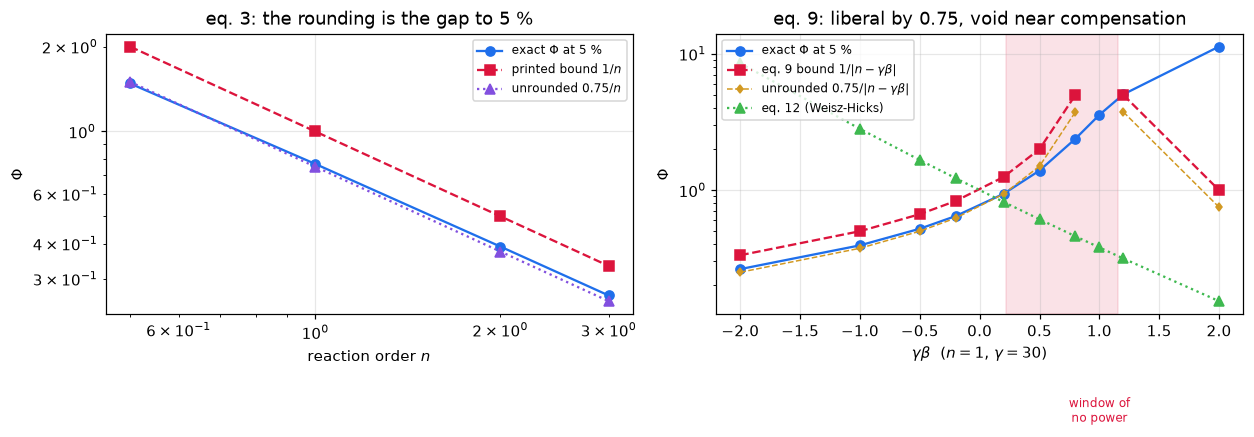

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ns = np.array(ORDERS)
axes[0].loglog(ns, [ISO[n]["Phi5"] for n in ns], "o-", color="#1f6feb", label=r"exact $\Phi$ at 5 %")
axes[0].loglog(ns, 1 / ns, "s--", color="crimson", label=r"printed bound $1/n$")
axes[0].loglog(ns, 0.75 / ns, "^:", color="#8250df", label=r"unrounded $0.75/n$")
axes[0].set_xlabel(r"reaction order $n$")
axes[0].set_ylabel(r"$\Phi$")
axes[0].set_title("eq. 3: the rounding is the gap to 5 %")
axes[0].legend(fontsize=8)
gbs = np.array(sorted(MAP9))
axes[1].semilogy(gbs, [MAP9[g]["Phi5"] for g in gbs], "o-", color="#1f6feb", label=r"exact $\Phi$ at 5 %")
bs = np.array([MAP9[g]["bound9"] for g in gbs])
axes[1].semilogy(gbs, bs, "s--", color="crimson", label=r"eq. 9 bound $1/|n-\gamma\beta|$")
axes[1].semilogy(gbs, 0.75 * bs, "d--", color="#d29922", lw=1.0, ms=4, label=r"unrounded $0.75/|n-\gamma\beta|$")
axes[1].semilogy(gbs, [MAP9[g]["bound12"] for g in gbs], "^:", color="#3fb950", label="eq. 12 (Weisz-Hicks)")
axes[1].axvspan(W_LO, W_HI, color="crimson", alpha=0.12)
axes[1].text(1.0, 2e-2, "window of\nno power", ha="center", fontsize=8, color="crimson")
axes[1].set_xlabel(r"$\gamma\beta$  ($n = 1$, $\gamma = 30$)")
axes[1].set_ylabel(r"$\Phi$")
axes[1].set_title("eq. 9: liberal by 0.75, void near compensation")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

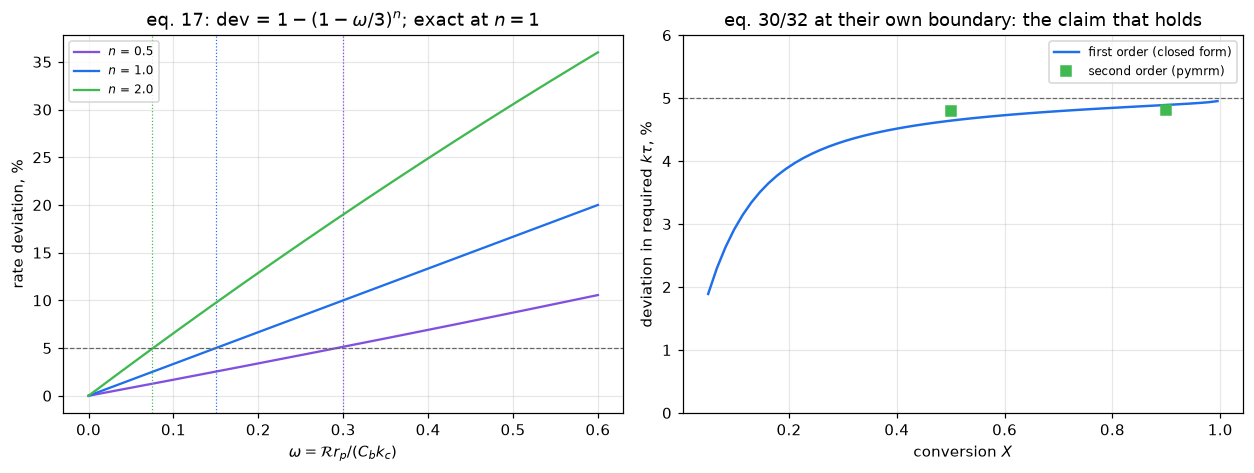

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
om = np.linspace(0, 0.6, 200)
for n, c in zip((0.5, 1.0, 2.0), ("#8250df", "#1f6feb", "#3fb950")):
    axes[0].plot(om, film_mass_dev(om, n) * 100, color=c, label=rf"$n$ = {n}")
    axes[0].axvline(0.15 / n, color=c, ls=":", lw=0.8)
axes[0].axhline(5, color="0.4", lw=0.8, ls="--")
axes[0].set_xlabel(r"$\omega = \mathcal{R}r_p/(C_bk_c)$")
axes[0].set_ylabel("rate deviation, %")
axes[0].set_title(r"eq. 17: dev = $1-(1-\omega/3)^n$; exact at $n=1$")
axes[0].legend(fontsize=8)
Xs = np.linspace(0.05, 0.995, 60)
axes[1].plot(Xs, [axial_dev(X) * 100 for X in Xs], color="#1f6feb", lw=1.6, label="first order (closed form)")
axes[1].plot(list(AX2), [d * 100 for d in AX2.values()], "s", color="#3fb950", label="second order (pymrm)")
axes[1].axhline(5, color="0.4", lw=0.8, ls="--")
axes[1].set_xlabel("conversion $X$")
axes[1].set_ylabel(r"deviation in required $k\tau$, %")
axes[1].set_ylim(0, 6)
axes[1].set_title("eq. 30/32 at their own boundary: the claim that holds")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Validation

**Tier 6: nothing on this page is compared with a measurement**; the source
contains none. The evidence, strongest first:

1. **Three routes to the headline number**, the deviation admitted by eq. 1:
   closed form, shooting and pymrm (Section 2).
2. **pymrm against the shooting reference** at eight audited threshold states,
   Dirichlet and film surfaces, isothermal and not, on a grid ladder; and the
   axial vessel against the classical closed form on its own ladder. Each
   observed order is backed by a bound that the finest-grid difference is at
   least 1e3 times the round-off of the quantity, measured as its spread under
   the solver tolerance, the LU column ordering and the initial guess (pellet),
   or under the solver route and tolerance (vessel).
3. **The two solvers of each discrete system agree**: the exact-Jacobian and
   the `NumJac` pellet; Newton with `ConvFluxTVD` and deferred correction for
   the vessel. Each pair solves the same discrete equations, so this checks the
   solvers, not the discretisation.
4. **The paper's printed numbers reproduced from other printed numbers**
   (Section 1). None is used as an input to anything.
5. **The break table** below: one injected defect per row, through an argument
   or a physical parameter, and whether the claim's own check catches it.

What no row can detect: a *convention* shared by every route. If "deviation"
meant something else to Mears than to this page, or $r_p$ meant a diameter,
every route would move together and agree. Those readings are guarded only by
the transcription (the nomenclature page prints "$r_p$ = particle radius, cm")
and by Section 1's paper-internal identities.

In [23]:
# pymrm against shooting at eight threshold states, reference at DOP853 rtol 1e-12.
def ref_states(rtol=RT_REF):
    out = []
    for n in ORDERS:
        out.append((f"iso n={n:g}", Power(n), None,
                    cross(Power(n), lambda p, e, P, o, ys: e - 0.95, lo=1e-3, rtol=rtol)))
    for gb in (-1.0, 0.5, 1.0):
        R = WeiszHicks(1.0, gb, GAMMA)
        out.append((f"WH gb={gb:g}", R, None,
                    cross(R, lambda p, e, P, o, ys: abs(e - 1) - 0.05, lo=1e-4, hi=22.0, rtol=rtol)))
    out.append(("film Bi_m=3", Power(1.0), 3.0,
                cross(Power(1.0), lambda p, e, P, o, ys: e - 0.95, lo=1e-3, hi=18.0, bim=3.0, rtol=rtol)))
    return out


STATES = ref_states()
SEEDS = {}
for name, R, bim, s in STATES:
    sol = shoot(R, s[0], bim=bim, rtol=RT_REF, dense=True)[5]
    SEEDS[name] = (sol, s[1])


def pm_eta(name, R, bim, n, read="face", nu=2, tol=1e-12, permc="COLAMD", seed=True, jacobian="exact",
           maxfev=60):
    """eta of the pymrm pellet at a reference state's phi, seeded from the shooting profile."""
    sol, phi = SEEDS[name]
    p = Pellet(n, nu=nu, bim=bim)
    y0 = (np.clip(sol.sol(np.clip(p.u_c * phi, sol.t[0], phi))[0], 0.0, 1.0) if seed else np.ones(n))
    y, _ = p.solve(phi, R, y_init=y0.reshape(-1, 1), tol=tol, jacobian=jacobian, maxfev=maxfev,
                   check=maxfev > 1, lin_solver_kwargs={"permc_spec": permc})
    return p.eta(y, phi, read=read)


def ladder(ns=(100, 200, 400, 800), **kw):
    return {name: {n: pm_eta(name, R, bim, n, **kw) for n in ns} for name, R, bim, _ in STATES}


def roundoff(n):
    """Largest relative spread of eta on n cells under newton tol 1e-12 vs 1e-10, COLAMD vs
    NATURAL column ordering, and a seeded vs a flat initial guess, per state."""
    out = {}
    for name, R, bim, _ in STATES:
        v = [pm_eta(name, R, bim, n, tol=t, permc=pc, seed=sd)
             for t in (1e-12, 1e-10) for pc in ("COLAMD", "NATURAL") for sd in (True, False)]
        out[name] = max(max(abs(x / v[0] - 1) for x in v), 2.2e-16)
    return out


def ladder_stats(lad, ns, ro):
    errs = {name: {n: abs(lad[name][n] / s[2] - 1) for n in ns} for name, _, _, s in STATES}
    orders = {name: observed_orders(lambda n: lad[name][n], ns)["orders"] for name in lad}
    ratio = {name: abs(lad[name][ns[-2]] - lad[name][ns[-1]]) / abs(lad[name][ns[-1]]) / ro[name] for name in lad}
    return errs, orders, ratio


NS = (100, 200, 400, 800)
LAD = ladder(NS)
RO = roundoff(800)
ERR, ORD, RATIO = ladder_stats(LAD, NS, RO)
print(f"{'state':>13} {'phi':>9} " + " ".join(f"{'n = %d' % n:>10}" for n in NS) + "   orders (successive differences)")
for name, _, _, s in STATES:
    print(f"{name:>13} {s[1]:9.5f} " + " ".join(f"{ERR[name][n]:10.1e}" for n in NS)
          + "   " + ", ".join(f"{o:.2f}" for o in ORD[name]))
_iso = [k for k in ERR if k.startswith("iso")]
_wh = [k for k in ERR if k.startswith("WH")]
_all_ord = [o for v in ORD.values() for o in v]
claims.value("pymrm_vs_shooting_iso_n800", float("%.2g" % max(ERR[k][800] for k in _iso)))  # 2 digits: round-off of eta
claims.value("pymrm_vs_shooting_wh_n800", float("%.2g" % max(ERR[k][800] for k in _wh)))  # 2 digits: round-off of eta
claims.value("pymrm_vs_shooting_robin_n800", float("%.2g" % ERR["film Bi_m=3"][800]))  # 2 digits: round-off of eta
claims.bound("pymrm_vs_shooting_iso_order", min(_all_ord), min=1.95, max=2.05, basis="theory",
             note="smallest observed order over the eight states, 100 to 800 cells; second order expected")
claims.bound("pymrm_vs_shooting_order_max", max(_all_ord), min=1.95, max=2.05, basis="theory",
             note="largest observed order over the eight states, 100 to 800 cells")
claims.bound("pymrm_vs_shooting_finest_over_roundoff_min", min(RATIO.values()), min=1e3, basis="theory",
             note="|eta(400) - eta(800)| over the round-off of eta on 800 cells, per state")


def ref_shift(rtol):
    """Largest |eta change| of the reference states when RT_REF is replaced by ``rtol``, over the 800-cell error."""
    return max(abs(st[3][2] / s[2] - 1) / ERR[name][800]
               for (name, _, _, s), st in zip(STATES, ref_states(rtol)))


claims.bound("reference_tol_shift_frac_of_err_n800", ref_shift(1e-13), max=1e-2, basis="chosen",
             note="reference states recomputed at DOP853 rtol 1e-13: the change in eta over the 800-cell "
                  "error, worst of the eight states")
brk("shooting reference at rtol 1e-8 instead of 1e-12", "reference_tol_shift_frac_of_err_n800", ref_shift(1e-8))
print(f"reference tolerance 1e-12 to 1e-13 moves eta by at most {claims['reference_tol_shift_frac_of_err_n800']:.0e} "
      "of the 800-cell error.")
LAD_CELL = ladder(NS, read="cell")
E_C, O_C, _ = ladder_stats(LAD_CELL, NS, RO)
_lab = "eta read by a two-point gradient from the last cell centre"
brk(_lab, "pymrm_vs_shooting_iso_n800", max(E_C[k][800] for k in _iso))
brk(_lab, "pymrm_vs_shooting_wh_n800", max(E_C[k][800] for k in _wh))
brk(_lab, "pymrm_vs_shooting_robin_n800", E_C["film Bi_m=3"][800])
brk(_lab, "pymrm_vs_shooting_iso_order", min(o for v in O_C.values() for o in v))
brk(_lab, "pymrm_vs_shooting_order_max", max(o for v in O_C.values() for o in v))
NS_F = (400, 800, 1600, 3200)
_lf = ladder(NS_F)
_, _, _rf = ladder_stats(_lf, NS_F, roundoff(3200))
brk("orders read at 3200 cells instead of 800 (finest grid two factors of 2 up)",
    "pymrm_vs_shooting_finest_over_roundoff_min", min(_rf.values()))
print(f"\nworst at 800 cells: {claims['pymrm_vs_shooting_iso_n800']:.1e} (isothermal), "
      f"{claims['pymrm_vs_shooting_wh_n800']:.1e} (Weisz-Hicks), "
      f"{claims['pymrm_vs_shooting_robin_n800']:.1e} (film)")
print(f"observed orders {min(_all_ord):.2f} to {max(_all_ord):.2f}; the round-off of eta on 800 cells is at most "
      f"(here {max(RO.values()):.0e}),")
print(f"so the finest difference is at least 1e3 times it in every state (here from "
      f"{claims['pymrm_vs_shooting_finest_over_roundoff_min']:.0e} times).")

# exact Jacobian against NumJac on the same discrete equations
GAP_NJ = max(abs(pm_eta(name, R, bim, 800, jacobian="numjac") / LAD[name][800] - 1) for name, R, bim, _ in STATES)
claims.bound("pellet_exact_vs_numjac", GAP_NJ, max=1e-10, basis="tolerance",
             note="newton tol 1e-12, both Jacobians, eight states on 800 cells")
brk("NumJac route stopped after one newton iteration from y = 1 (maxfev=1)", "pellet_exact_vs_numjac",
    max(abs(pm_eta(name, R, bim, 800, jacobian="numjac", maxfev=1, seed=False) / LAD[name][800] - 1)
        for name, R, bim, _ in STATES))
print(f"exact Jacobian (construct_coefficient_matrix) against NumJac((n, 1)): eta equal to below 1e-10 "
      f"(here {GAP_NJ:.0e})")
_lnj = ladder((800,), nu=0)
brk("pymrm pellet assembled as a slab (nu = 0)", "pymrm_vs_shooting_iso_n800",
    max(abs(_lnj[k][800] / s[2] - 1) for k, _, _, s in STATES if k.startswith("iso")))
brk("pymrm pellet assembled as a slab (nu = 0)", "pymrm_vs_shooting_wh_n800",
    max(abs(_lnj[k][800] / s[2] - 1) for k, _, _, s in STATES if k.startswith("WH")))
brk("pymrm pellet assembled as a slab (nu = 0)", "pymrm_vs_shooting_robin_n800",
    abs(_lnj["film Bi_m=3"][800] / STATES[-1][3][2] - 1))

        state       phi    n = 100    n = 200    n = 400    n = 800   orders (successive differences)
    iso n=0.5   1.24808    5.1e-06    1.3e-06    3.2e-07    7.9e-08   2.00, 2.00
      iso n=1   0.89859    5.2e-06    1.3e-06    3.2e-07    8.1e-08   2.00, 2.00
      iso n=2   0.64114    5.2e-06    1.3e-06    3.3e-07    8.2e-08   2.00, 2.00
      iso n=3   0.52506    5.2e-06    1.3e-06    3.3e-07    8.2e-08   2.00, 2.00
     WH gb=-1   0.64380    5.3e-06    1.3e-06    3.3e-07    8.2e-08   2.00, 2.00
    WH gb=0.5   1.21101    4.9e-06    1.2e-06    3.1e-07    7.7e-08   2.00, 2.00
      WH gb=1   1.93831    2.1e-06    5.3e-07    1.3e-07    3.3e-08   2.00, 2.00
  film Bi_m=3   0.54496    1.9e-06    4.8e-07    1.2e-07    3.0e-08   2.00, 2.00


reference tolerance 1e-12 to 1e-13 moves eta by at most 3e-05 of the 800-cell error.



worst at 800 cells: 8.2e-08 (isothermal), 8.2e-08 (Weisz-Hicks), 3.0e-08 (film)
observed orders 2.00 to 2.00; the round-off of eta on 800 cells is at most (here 2e-11),
so the finest difference is at least 1e3 times it in every state (here from 6e+03 times).
exact Jacobian (construct_coefficient_matrix) against NumJac((n, 1)): eta equal to below 1e-10 (here 1e-11)


True

In [24]:
# The axial vessel against the closed form at X = 0.632 (Pe_L = 20), and its two solvers.
X_CHK, NZ = 0.632, (200, 400, 800, 1600)


def axial_ladder(ns=NZ, **kw):
    return {n: axial_dev(X_CHK, n_z=n, **kw) for n in ns}


AXL = axial_ladder()
AX_ERR = {n: abs(v - AX1[X_CHK]) for n, v in AXL.items()}
AX_ORD = observed_orders(lambda n: AXL[n], NZ)["orders"]


def axial_roundoff(n):
    v = [axial_dev(X_CHK, n_z=n, tol=1e-12), axial_dev(X_CHK, n_z=n, tol=1e-10),
         axial_dev(X_CHK, n_z=n, route="deferred")]
    return max(max(abs(x - v[0]) for x in v), 1e-17)


AX_RO = axial_roundoff(NZ[-1])
print(f"pymrm vessel against the closed form at X = {X_CHK} (dev = {AX1[X_CHK] * 100:.3f} %):")
print("  " + "  ".join(f"n_z={n}: {e:.2e}" for n, e in AX_ERR.items())
      + "   orders " + ", ".join(f"{o:.2f}" for o in AX_ORD))
claims.value("pymrm_axial_vs_closed_form", AX_ERR[1600])
claims.bound("axial_order_min", min(AX_ORD), min=1.75, max=2.05, basis="chosen",
             note="van Leer: second order where the limiter is inactive; the observed orders rise towards 2 "
                  "with refinement, pre-asymptotic on this ladder")
claims.bound("axial_order_max", max(AX_ORD), min=1.75, max=2.05, basis="chosen",
             note="as axial_order_min")
claims.bound("axial_finest_over_roundoff", abs(AXL[800] - AXL[1600]) / AX_RO, min=1e3, basis="theory",
             note="|dev(800) - dev(1600)| over the spread of dev on 1600 cells under newton tol and solver route")
_up = axial_ladder(limiter=None)
_up_ord = observed_orders(lambda n: _up[n], NZ)["orders"]
brk("first-order upwind convection (no TVD limiter)", "pymrm_axial_vs_closed_form", abs(_up[1600] - AX1[X_CHK]))
brk("first-order upwind convection (no TVD limiter)", "axial_order_min", min(_up_ord))
brk("first-order upwind convection (no TVD limiter)", "axial_order_max", max(_up_ord))
brk("outlet read at the last cell centre", "pymrm_axial_vs_closed_form",
    abs(axial_dev(X_CHK, n_z=1600, read="cell") - AX1[X_CHK]))
brk("Dirichlet inlet instead of Danckwerts", "pymrm_axial_vs_closed_form",
    abs(axial_dev(X_CHK, n_z=1600, inlet="dirichlet") - AX1[X_CHK]))
_NZF = (1600, 3200, 6400, 12800)
_axf = axial_ladder(_NZF)
brk("orders read at 12800 cells instead of 1600 (finest grid three factors of 2 up)",
    "axial_finest_over_roundoff", abs(_axf[6400] - _axf[12800]) / axial_roundoff(12800))
print(f"error {claims['pymrm_axial_vs_closed_form']:.2e} on 1600 cells; the spread of dev under newton tol "
      f"and solver route is at most (here {AX_RO:.0e}),")
print(f"so the finest difference is at least 1e3 times it (here {claims['axial_finest_over_roundoff']:.0e} times).")

# the two solvers of the vessel's discrete equations
_pairs = [(X, n, 1) for X in (0.2, 0.632, 0.99) for n in NZ] + [(X, 800, 2) for X in (0.5, 0.9)]
GAP_ND = max(abs(axial_dev(X, n_react=r, n_z=n) - axial_dev(X, n_react=r, n_z=n, route="deferred"))
             for X, n, r in _pairs)
claims.bound("axial_newton_vs_deferred", GAP_ND, max=1e-8, basis="tolerance",
             note="newton tol 1e-12 against sweeps to a change below 1e-13; three conversions on 200 to "
                  "1600 cells, and second order at two conversions on 800 cells")
brk("deferred-correction route only with a Dirichlet inlet", "axial_newton_vs_deferred",
    abs(axial_dev(0.632, n_z=800) - axial_dev(0.632, n_z=800, route="deferred", inlet="dirichlet")))
print(f"\nNewton with ConvFluxTVD and van Leer deferred correction solve the same discrete equations; "
      f"over {len(_pairs)} cases")
print(f"their deviations agree to below 1e-8 (here {GAP_ND:.0e}). Both converge on these smooth steady profiles")
print("(newton step tolerance 1e-12; sweeps until the largest change is below 1e-13). Deferred correction")
print("is a fixed-point iteration whose convergence depends on the profile (pymrm pitfall P10); the exact")
print("Jacobian of ConvFluxTVD makes the production route a Newton solve.")

pymrm vessel against the closed form at X = 0.632 (dev = 4.751 %):
  n_z=200: 3.68e-06  n_z=400: 1.03e-06  n_z=800: 2.74e-07  n_z=1600: 7.11e-08   orders 1.81, 1.89


error 7.11e-08 on 1600 cells; the spread of dev under newton tol and solver route is at most (here 8e-12),
so the finest difference is at least 1e3 times it (here 3e+04 times).



Newton with ConvFluxTVD and van Leer deferred correction solve the same discrete equations; over 14 cases
their deviations agree to below 1e-8 (here 4e-10). Both converge on these smooth steady profiles
(newton step tolerance 1e-12; sweeps until the largest change is below 1e-13). Deferred correction
is a fixed-point iteration whose convergence depends on the profile (pymrm pitfall P10); the exact
Jacobian of ConvFluxTVD makes the production route a Newton solve.


### The break table

Every number above is registered as a claim; each row injects one defect
through an argument or a parameter and reports what the claim becomes, and
whether the claim's own check catches it. Rows a claim does not catch are kept:
they show what that check is blind to.

In [25]:
print(f"{'injected defect':<76} {'claim':<44} {'clean':>11} {'broken':>12}  caught")
# grid errors carry the round-off of eta (a few 1e-4 of their size): shown to 2 digits
_coarse_print = {"pymrm_vs_shooting_iso_n800", "pymrm_vs_shooting_wh_n800", "pymrm_vs_shooting_robin_n800",
                 "pymrm_axial_vs_closed_form", "headline_three_route_spread"}
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    fmt = "11.2g" if metric in _coarse_print else "11.5g"
    shown = f"(here {clean:.0e})" if is_bound else f"{float(clean):{fmt}}"
    br = f"(here {float(broken):.0e})" if is_bound else f"{float(broken):12.5g}"
    print(f"{name[:76]:<76} {metric[:44]:<44} {shown:>11} {br:>12}  {'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"structural: {', '.join(_structural) or 'none'}; open: {', '.join(_open) or 'none'}")
print("rows that do not fail their claim: "
      + ("; ".join(f"{n} -> {m}" for n, m, _, _, c in BREAK if not c) or "none"))

injected defect                                                              claim                                              clean       broken  caught
pellet traced as a slab (nu = 0)                                             perturbation_slope_rel_err                   (here 3e-06) (here 4e+00)  yes
pellet traced as a slab (nu = 0)                                             iso_Phi5_n1                                      0.76709      0.15159  yes
source exponent 2 where 1 is claimed                                         iso_Phi5_n1                                      0.76709       0.3905  yes
pellet traced as a slab (nu = 0)                                             eq1_dev_at_bound_n1                             0.064722      0.30518  yes
pellet traced as a slab (nu = 0)                                             eq3_dev_at_bound_n05                            0.067876       0.3778  yes
pellet traced as a slab (nu = 0)                                             eq3_dev

## What pymrm adds

**Nothing to the criteria themselves**: each is one line of algebra, reproduced
as printed. What the page adds is the exact solve behind every stated
tolerance, which turns a family of rules of thumb into a table of measured
guarantees. Most of the audit is carried by the shooting reference (SciPy
integration, `pymrm.checks.find_roots` scans) and by closed forms. pymrm
supplies the second route: the finite-volume pellet, whose surface physics
(Dirichlet or film) is entirely a boundary-condition dict on the outward
normal, with the exact Jacobian through `construct_coefficient_matrix`,
`newton` with bounds and the surface flux from `compute_boundary_values`; and
the dispersion vessel with `ConvFluxTVD` and `newton`, the only route for
second order. The pellet converges at second order against its reference; the
vessel's observed orders rise towards 2 on the ladders of the Validation
section (pre-asymptotic), which is what makes the audit's numbers evidence
rather than output.

In [26]:
display(Markdown(f"""
- **Eq. 17 is exact at first order**: the film balance makes the deviation $\\omega/3$
  identically, so its boundary admits 5 % to all digits. Zero order is exactly unaffected.
  Carberry's older 0.1 admits {claims['eq16_carberry_dev_surface'] * 100:.2f} % or
  {claims['eq16_carberry_dev'] * 100:.1f} %, depending on the reading of his $\\eta$.
- **The intraparticle family (eqs. 1-3) is liberal by its own rounding.** At the printed bounds
  the deviation is {min(_db) * 100:.2f}-{max(_db) * 100:.2f} % (eq. 1 alone:
  {claims['eq1_dev_at_bound_n1'] * 100:.2f} %); at the unrounded $0.75/n$ it is
  {min(_d75) * 100:.2f}-{max(_d75) * 100:.2f} %. An experimenter who wants the stated 5 % should use
  $0.75/n$, the number the paper had before rounding it away.
- **Eq. 9's exclusion zone has a width**: even with the unrounded 0.75 the bound certifies
  deviations beyond 5 % for $\\gamma\\beta$ in ({W_LO:.3f}, {W_HI:.3f}) at $n = 1$, $\\gamma = 30$,
  and Petersen's 13 there admits {claims['petersen13_dev_gamma30'] * 100:.0f} %, a transition-region
  marker. Past $\\gamma\\beta = {SECOND_ONSET:.2f}$ the unrounded bound re-admits a mild
  {min(OUT2.values()) * 100:.2f}-{max(OUT2.values()) * 100:.2f} %. On the folded branch of
  $\\gamma\\beta = 24$, eq. 1's band certifies a deviation of {claims['eq1_fold_worst_certified_dev']:.0f}
  while eq. 9's band admits {claims['eq9_fold_worst_certified_dev'] * 100:.2f} % at its edge.
- **Eq. 14 is liberal by construction but only just** ({claims['eq14_dev_exo_gamma10'] * 100:.2f}-{claims['eq14_dev_exo_gamma40'] * 100:.2f} % for $\\gamma$ = 10-40), and the film observables
  determine the deviation: the multiplicity blind spot of the pellet observable does not exist at the
  film.
- **Eq. 21 fails structurally at low $\\mathrm{{Bi}}_m$** (ratio of the exact 5 % state to its bound
  {claims['eq21_ratio_Bim03']:.3f} at $\\mathrm{{Bi}}_m = 0.3$) and must be applied with eq. 17. Passing
  eqs. 1, 17 and 21 at once still admits {JOINT_WORST * 100:.1f} %, at an interior optimum
  $\\mathrm{{Bi}}_m = {JOINT_BIM:.2f}$ where two criteria bind at once.
- **Eq. 30/32, Mears' axial criterion, holds its claim everywhere tested**:
  {claims['eq30_dev_X02'] * 100:.2f}-{claims['eq30_dev_X099'] * 100:.2f} % at first order,
  {claims['eq32_dev_n2_worst'] * 100:.2f} % at most at second order; Petersen's $\\alpha < 1$ admits
  {claims['eq28_petersen_dev_X0393'] * 100:.0f}-{claims['eq28_petersen_dev_X09'] * 100:.0f} %.
"""))


- **Eq. 17 is exact at first order**: the film balance makes the deviation $\omega/3$
  identically, so its boundary admits 5 % to all digits. Zero order is exactly unaffected.
  Carberry's older 0.1 admits 9.09 % or
  10.0 %, depending on the reading of his $\eta$.
- **The intraparticle family (eqs. 1-3) is liberal by its own rounding.** At the printed bounds
  the deviation is 6.29-6.79 % (eq. 1 alone:
  6.47 %); at the unrounded $0.75/n$ it is
  4.78-5.07 %. An experimenter who wants the stated 5 % should use
  $0.75/n$, the number the paper had before rounding it away.
- **Eq. 9's exclusion zone has a width**: even with the unrounded 0.75 the bound certifies
  deviations beyond 5 % for $\gamma\beta$ in (0.222, 1.159) at $n = 1$, $\gamma = 30$,
  and Petersen's 13 there admits 38 %, a transition-region
  marker. Past $\gamma\beta = 1.95$ the unrounded bound re-admits a mild
  5.03-5.22 %. On the folded branch of
  $\gamma\beta = 24$, eq. 1's band certifies a deviation of 3135
  while eq. 9's band admits 7.20 % at its edge.
- **Eq. 14 is liberal by construction but only just** (5.10-5.12 % for $\gamma$ = 10-40), and the film observables
  determine the deviation: the multiplicity blind spot of the pellet observable does not exist at the
  film.
- **Eq. 21 fails structurally at low $\mathrm{Bi}_m$** (ratio of the exact 5 % state to its bound
  0.044 at $\mathrm{Bi}_m = 0.3$) and must be applied with eq. 17. Passing
  eqs. 1, 17 and 21 at once still admits 11.1 %, at an interior optimum
  $\mathrm{Bi}_m = 6.33$ where two criteria bind at once.
- **Eq. 30/32, Mears' axial criterion, holds its claim everywhere tested**:
  3.91-4.95 % at first order,
  4.81 % at most at second order; Petersen's $\alpha < 1$ admits
  23-51 %.


## Reuse

| Change | Where |
|---|---|
| Audit your own criterion | write it as `val(phi, eta, Phi, omega, y_s)` and hand it to `cross`, which finds the state where it binds; the default returns the *deep-side* (largest-$\Phi$) state, so use `which="all"` wherever the condition can cross more than once |
| Different kinetics | any object with `r(y)` and `dr(y)` into `shoot`, `cross` and `Pellet.solve`; keep $\mathcal{F}(1)=1$ so $\Phi$ stays the printed observable |
| Film instead of Dirichlet surface | `Pellet(bim=...)` and `shoot(..., bim=...)`: one bc dict, `{a:1, b:Bim, d:Bim}` on the outward normal |
| Slab or cylinder | `nu=0` or `1`; the printed thresholds are for the sphere, and the break table shows how much that matters |
| A tolerance other than 5 % | change the `0.05` in the `cross` conditions; the bounds scale linearly only at first order |
| Axial criterion at your conversion and order | `axial_dev(X, n_react=..., n_z=...)`; the closed form is first order only |

**How to screen a measurement, given what is above.** Use eq. 17 as printed: it
is exact at first order and close otherwise. For the pellet, use $0.75/n$, not
$1/n$, if the 5 % is meant literally, and take $r_p$ as a radius. If the reaction
is exothermic, compute $\gamma\beta$ first: inside the window printed in
Section 4 not even the unrounded constant makes eq. 9 a 5 % test, so measure at
two particle sizes instead (the paper's own empirical fallback). Apply eq. 17
*alongside* eq. 21, never eq. 21 alone, and remember that passing every test
still admits the stacked deviation of Section 5 when two resistances sit at
their boundaries at once. The axial criterion can be trusted as printed.

**Reading the paper.** The scan's text layer destroys the criteria; read every
threshold off a 300 dpi render (the native resolution, so higher renders only
interpolate). The PDF opens with the tail of the preceding article; the paper
starts partway down page 1 of the file.

**Related pages.** [`B1.4`](../B1.4-weisz-prater-criterion/), the same audit
for eq. 1 alone, with the fold analysis this page leans on;
[`B1.1`](../B1.1-thiele-weisz-hicks/), the forward problem behind Section 4;
[`B1.6`](../B1.6-prater-relation/), the reduction used in the pellet model;
[`A2.1`](../A2.1-danckwerts-boundary-conditions/), the axial vessel and its
boundary conditions; `B1.2`/`B1.3`, the generalised moduli, i.e. the
length-scale question underneath every threshold here.

## References

Mears, D. E. (1971). *Tests for transport limitations in experimental
catalytic reactors.* Ind. Eng. Chem. Process Des. Develop. **10**(4), 541-547.
[doi:10.1021/i260040a020](https://doi.org/10.1021/i260040a020). **The source
read**; every criterion and threshold transcribed from 300 dpi native renders
of journal pages 541-547.

Mears, D. E. (1971a). Chem. Eng. Sci., cited by the source as "in press"; the
**origin of the axial criterion** (eqs. 29-32). **Not consulted.**

Mears, D. E. (1971b). J. Catal. **20**, 127; the **origin of the interphase
and interparticle heat criteria** (eqs. 14, 23). **Not consulted.**

Cited by the source for the criteria it reviews, none consulted: Weisz &
Prater (1954); Weisz (1957); Weisz & Hicks (1962), the source of
`B1.1`/`B1.4`/`B1.6`, not needed here; Hudgins (1968); Anderson (1963); Kubota
& Yamanaka (1969); Carberry (1961); Satterfield, Pelossof & Sherwood (1969);
Petersen (1965b, 1968); Stewart & Villadsen (1969); van den Bleek, van der
Wiele & van den Berg (1969).

In [27]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B1.7:
  alpha_star_identity                        = (here 2.2e-01)   bound  bound [0.2236, 0.2237] [identity]
  perturbation_slope_rel_err                 = (here 3.2e-06)   bound  bound <= 0.0001 [chosen]
  bi_star_identity                           = (here 1.0e+01)   bound  bound [10, 10] [identity]
  symbolic_reductions_hold                   = True             exact  exact
  iso_Phi5_n1                                = 0.76709          value  rtol 1e-05
  eq1_dev_at_bound_n1                        = 0.064722         value  rtol 1e-05
  eq3_dev_at_bound_n05                       = 0.067876         value  rtol 1e-05
  eq3_dev_at_bound_n2                        = 0.063306         value  rtol 1e-05
  eq3_dev_at_bound_n3                        = 0.062854         value  rtol 1e-05
  eq3_dev_at_unrounded_075_n05               = 0.050691         value  rtol 1e-05
  eq3_dev_at_unrounded_075_n1                = 0.048912         value  rtol 1e-05
  eq3_dev_at_unrounded_075_n2     